# Trabajo practico especial - Analisis de enfermedad renal cronica

## Exploración inicial de los datos

Lo principal y más importante para explorar los datos es primeramente, obtener el dataset y su metadata.

In [72]:
# Instalación de librerías necesarias
!pip install wget pandas

from wget import download
from os import path, makedirs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [73]:
makedirs("resources", exist_ok=True)

archivo_metadata = "resources/metadata.docx"
archivo_dataset = "resources/CKD_NHANES_2021_2023.csv"

if not path.exists(archivo_metadata):
    download(
        "https://drive.google.com/uc?export=download&id=1dJRgbPz48x1vbX0E3_4OZ1u4Q33hyQCI",
        archivo_metadata
    )
else:
    print("el archivo de la metadata ya existe")

if not path.exists(archivo_dataset):
    download(
        "https://drive.google.com/uc?export=download&id=1p5GjM2xPLSIm44ET6n5A1NDi3eOf6ghU",
        archivo_dataset
    )

else:
    print("el dataset ya existe")

el archivo de la metadata ya existe
el dataset ya existe


In [74]:
# Instanciamos el dataset en un DataFrame de pandas
df = pd.read_csv(archivo_dataset)

### Identificación de participantes

Antes de explorar las variables, contamos los valores repetidos de `participant_id`. Si no hay identificadores repetidos, excluimos esta columna de `df_limpio` porque identifica participantes y no representa una medición. Si hay repetidos, la conservamos para revisarlos. El DataFrame original `df` mantiene todas sus columnas.


In [75]:
# Creamos la copia que usaremos para explorar y limpiar los datos.
df_limpio = df.copy()
long_df = len(df)
id_distintos = df["participant_id"].nunique()

print("Cantidad de filas:", long_df)
print("Identificadores distintos:", id_distintos)


if id_distintos  == long_df:
    df_limpio = df_limpio.drop(columns=["participant_id"])
    print("Todos los identificadores son únicos; se excluyen de df_limpio.")
else:
    print("Hay identificadores repetidos; se conserva participant_id para revisarlos.")


Cantidad de filas: 11933
Identificadores distintos: 11933
Todos los identificadores son únicos; se excluyen de df_limpio.


In [76]:
# Permite ver todas las columnas del DataFrame sin truncar la salida
pd.set_option("display.max_columns", None)
df_limpio.head()

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


Vemos que hay variables que son de tipo float64 y terminan desaprovechandose o se podria trabajar de mejor manera si reconvertimos el tipo de la variable.
En la metadata se observa una advertencia sobre valores positivos diminutos que representan cero, reemplacemos esos valores antes de realizar las conversiones a las columnas

In [77]:
# Conocer un poco mas las variables
df_limpio.describe(include="all")

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
count,1.193300e+04,11933,11933,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,6326.000000,6366.000000,6322.000000,6325.000000,6362.000000,6329.000000,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933,11933.000000
unique,NaN,2,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,NaN
top,NaN,Female,Non-Hispanic White,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,NaN
freq,NaN,6358,6217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5607,NaN
mean,3.831786e+01,NaN,NaN,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,14.659817,4.099246,3.608573,24.449012,9.428969,5.133670,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,NaN,0.698986
std,2.560199e+01,NaN,NaN,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,5.754035,0.355161,0.569378,2.411849,0.381800,1.407571,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,NaN,0.458718
min,5.397605e-79,NaN,NaN,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,4.000000,2.200000,1.600000,15.000000,7.500000,1.100000,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,NaN,0.000000
25%,1.300000e+01,NaN,NaN,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,11.000000,3.900000,3.200000,23.000000,9.200000,4.100000,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,NaN,0.000000
50%,3.700000e+01,NaN,NaN,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,14.000000,4.100000,3.600000,24.000000,9.400000,5.000000,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,NaN,1.000000
75%,6.200000e+01,NaN,NaN,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,17.000000,4.300000,3.900000,26.000000,9.700000,6.000000,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,NaN,1.000000


El archivo metatada.docx menciona que el DataSet cuenta con un error por la conversion del archivo, tienen valores muy cercanos a 0, que deberian ser 0, pero estan mal convertidos. 

In [78]:
# Continuamos trabajando sobre la copia creada al verificar los identificadores.

# Corregir las edades positivas extremadamente cercanas a cero.
edades_cercanas_a_cero = (df_limpio["age"] > 0) & (df_limpio["age"] < 1e-10)
df_limpio.loc[edades_cercanas_a_cero, "age"] = 0

# Convertir los códigos y las edades a enteros, conservando nulos.
for columna in ["age", "education_level", "diabetes_diagnosed", "current_smoker"]:
    df_limpio[columna] = df_limpio[columna].astype("Int64")

# Convertir las respuestas sí/no a booleanos.
for columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
    df_limpio[columna] = df_limpio[columna].replace({
        1: True,
        2: False,
        7: pd.NA,
        9: pd.NA
    }).astype("boolean")

df_limpio.dtypes

age                           Int64
gender                          str
ethnicity                       str
education_level               Int64
poverty_income_ratio        float64
bmi                         float64
weight_kg                   float64
height_cm                   float64
bp_systolic                 float64
bp_diastolic                float64
serum_creatinine            float64
blood_urea_nitrogen         float64
albumin_serum               float64
phosphorus                  float64
bicarbonate                 float64
calcium                     float64
uric_acid                   float64
urine_creatinine            float64
urine_albumin               float64
albumin_creatinine_ratio    float64
diabetes_diagnosed            Int64
insulin_use                 boolean
diabetes_pills              boolean
ever_smoked                 boolean
current_smoker                Int64
egfr                        float64
ckd_stage                       str
ckd_present                 

In [79]:
df_limpio.head()

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,43,Male,Non-Hispanic Asian,5,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2,<NA>,<NA>,True,3,112.61,No CKD,0
1,66,Male,Non-Hispanic White,5,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2,<NA>,<NA>,True,3,97.98,No CKD,0
2,44,Female,Other Hispanic,3,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1,False,True,False,<NA>,111.69,No CKD,0
3,5,Female,Other/Multiracial,<NA>,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1
4,2,Male,Non-Hispanic White,<NA>,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1


Sabemos que cuando ckd_stage = Unknown -> ckd_present = 1; y eso no esta del todo bien, conviene dejar ese caso expresado como ckd_present = pd.NA por el momento


In [80]:
df_limpio["ckd_present"] = df_limpio["ckd_present"].astype("Int64")

df_limpio.loc[
    df_limpio["ckd_stage"] == "Unknown",
    "ckd_present"
] = pd.NA


## Resumen de variables

El porcentaje de nulos corresponde al DataFrame limpio (`df_limpio`). El identificador se revisa al inicio de la exploración y se excluye de esta tabla.

| Variable | Tipo computacional antes | Tipo computacional después | Porcentaje de nulos |
|---|---|---|---:|
| age | float64 | Int64 | 0.00% |
| gender | str | str | 0.00% |
| ethnicity | str | str | 0.00% |
| education_level | float64 | Int64 | 34.69% |
| poverty_income_ratio | float64 | float64 | 17.10% |
| bmi | float64 | float64 | 29.01% |
| weight_kg | float64 | float64 | 26.64% |
| height_cm | float64 | float64 | 28.78% |
| bp_systolic | float64 | float64 | 37.01% |
| bp_diastolic | float64 | float64 | 37.01% |
| serum_creatinine | float64 | float64 | 46.99% |
| blood_urea_nitrogen | float64 | float64 | 46.99% |
| albumin_serum | float64 | float64 | 46.65% |
| phosphorus | float64 | float64 | 47.02% |
| bicarbonate | float64 | float64 | 47.00% |
| calcium | float64 | float64 | 46.69% |
| uric_acid | float64 | float64 | 46.96% |
| urine_creatinine | float64 | float64 | 31.67% |
| urine_albumin | float64 | float64 | 31.68% |
| albumin_creatinine_ratio | float64 | float64 | 31.68% |
| diabetes_diagnosed | float64 | Int64 | 1.62% |
| insulin_use | float64 | boolean | 90.94% |
| diabetes_pills | float64 | boolean | 80.94% |
| ever_smoked | float64 | boolean | 31.95% |
| current_smoker | float64 | Int64 | 72.82% |
| egfr | float64 | float64 | 46.99% |
| ckd_stage | str | str | 0.00% |
| ckd_present | int64 | Int64 | 46.99% |

In [81]:
# Codigo para sacar porcentajes de nulos por columna
porcentaje_nulos = df_limpio.isna().mean().mul(100)

porcentaje_nulos.sort_values(ascending=False).round(2)


insulin_use                 90.94
diabetes_pills              80.94
current_smoker              72.82
phosphorus                  47.02
bicarbonate                 47.00
blood_urea_nitrogen         46.99
egfr                        46.99
ckd_present                 46.99
serum_creatinine            46.99
uric_acid                   46.96
calcium                     46.69
albumin_serum               46.65
bp_systolic                 37.01
bp_diastolic                37.01
education_level             34.69
ever_smoked                 31.95
albumin_creatinine_ratio    31.68
urine_albumin               31.68
urine_creatinine            31.67
bmi                         29.01
height_cm                   28.78
weight_kg                   26.64
poverty_income_ratio        17.10
diabetes_diagnosed           1.62
gender                       0.00
age                          0.00
ethnicity                    0.00
ckd_stage                    0.00
dtype: float64

## Frecuencias y distribuciones de las variables

Trabajamos con `df_limpio`, sin modificar sus valores. Distinguimos las variables por su significado, no solamente por el tipo de dato que usa pandas:

- **Identificador:** `participant_id`. Al inicio de la exploración se comprueba si hay valores repetidos. Si no hay repetidos, se retira de `df_limpio`; no se analiza como una variable cuantitativa.
- **Cuantitativa discreta:** `age`, registrada en años enteros.
- **Cuantitativas continuas:** medidas corporales, presiones, análisis de laboratorio, `poverty_income_ratio` y `egfr`.
- **Categóricas nominales:** `gender`, `ethnicity`, `diabetes_diagnosed` y las respuestas binarias `insulin_use`, `diabetes_pills`, `ever_smoked` y `ckd_present`.
- **Categóricas ordinales:** `education_level`, `current_smoker` y las etapas conocidas de `ckd_stage`. Los códigos 7/9 y `Unknown` no forman parte de ese orden.

Los porcentajes de frecuencias usan como denominador **todas las filas del archivo**, incluyendo las que no tienen respuesta. Mostramos por separado `Sin dato`, las respuestas 7/9 y `Unknown`. Un faltante en una pregunta condicional, como uso de insulina o tabaquismo actual, no equivale a una respuesta negativa.

Estas frecuencias describen el archivo: no son estimaciones ponderadas de la población de Estados Unidos.


In [82]:
import matplotlib.pyplot as plt
from IPython.display import display

variables_numericas = [
    "age", "poverty_income_ratio", "bmi", "weight_kg", "height_cm",
    "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen",
    "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid",
    "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "egfr"
]

# Las etiquetas respetan el diccionario de variables de la metadata.
etiquetas_categorias = {
    "gender": {"Female": "Femenino", "Male": "Masculino"},
    "ethnicity": {
        "Mexican American": "Mexicano estadounidense",
        "Other Hispanic": "Otro hispano",
        "Non-Hispanic White": "Blanco no hispano",
        "Non-Hispanic Black": "Negro no hispano",
        "Non-Hispanic Asian": "Asiático no hispano",
        "Other/Multiracial": "Otro / multirracial"
    },
    "education_level": {
        1: "Menos de noveno grado",
        2: "Noveno a undécimo grado",
        3: "Secundaria completa / equivalente",
        4: "Superior incompleto / terciario corto",
        5: "Universitario o superior",
        7: "Se negó a responder (7)",
        9: "No sabe (9)"
    },
    "diabetes_diagnosed": {
        1: "Sí", 2: "No", 3: "Diagnóstico límite",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "insulin_use": {True: "Sí", False: "No"},
    "diabetes_pills": {True: "Sí", False: "No"},
    "ever_smoked": {True: "Sí", False: "No"},
    "current_smoker": {
        1: "Todos los días", 2: "Algunos días", 3: "Actualmente no fuma",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "ckd_stage": {
        "No CKD": "No CKD",
        "Stage 1 (Kidney Damage)": "Etapa 1",
        "Stage 2 (Mildly Decreased)": "Etapa 2",
        "Stage 3a (Mild-Moderate)": "Etapa 3a",
        "Stage 3b (Moderate-Severe)": "Etapa 3b",
        "Stage 4 (Severely Decreased)": "Etapa 4",
        "Stage 5 (Kidney Failure)": "Etapa 5",
        "Unknown": "Etapa desconocida"
    },
    "ckd_present": {0: "Sin CKD según el archivo", 1: "Con CKD según el archivo"}
}


### Frecuencias de las variables categóricas

Cada tabla muestra la cantidad de personas y su porcentaje sobre el total de filas. Las barras conservan el orden de las categorías del diccionario y muestran también las categorías sin observaciones.

Las conversiones previas unificaron los códigos 7/9 y los nulos de las tres variables booleanas como `pd.NA`. Para no perder esa distinción en este análisis, recuperamos las respuestas originales de esas tres columnas desde `df`, solo para construir sus tablas de frecuencias. No cambiamos `df_limpio`.


gender


,Frecuencia,Porcentaje del total
gender,,
Femenino,6358,53.28
Masculino,5575,46.72
Sin dato,0,0.00


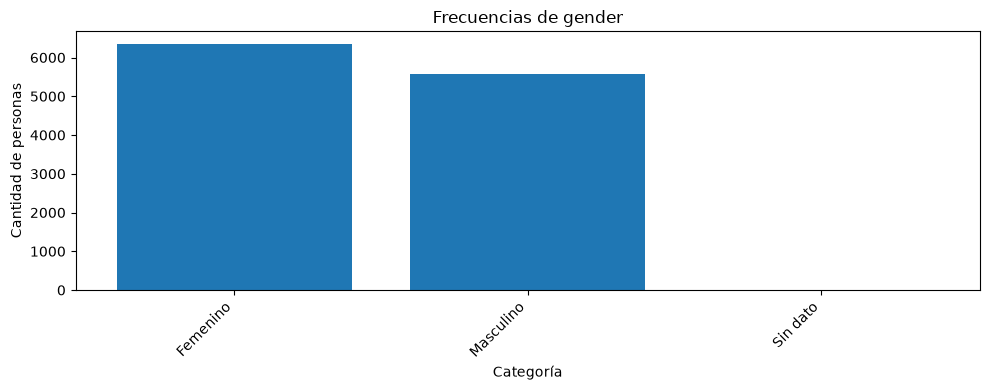

ethnicity


,Frecuencia,Porcentaje del total
ethnicity,,
Mexicano estadounidense,1117,9.36
Otro hispano,1373,11.51
Blanco no hispano,6217,52.10
Negro no hispano,1597,13.38
Asiático no hispano,681,5.71
Otro / multirracial,948,7.94
Sin dato,0,0.00


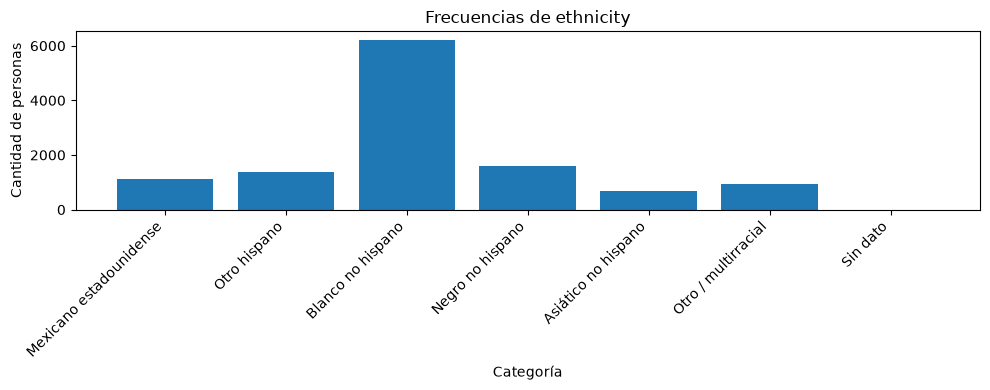

education_level


,Frecuencia,Porcentaje del total
education_level,,
Menos de noveno grado,373,3.13
Noveno a undécimo grado,666,5.58
Secundaria completa / equivalente,1749,14.66
Superior incompleto / terciario corto,2370,19.86
Universitario o superior,2625,22.00
Se negó a responder (7),0,0.00
No sabe (9),11,0.09
Sin dato,4139,34.69


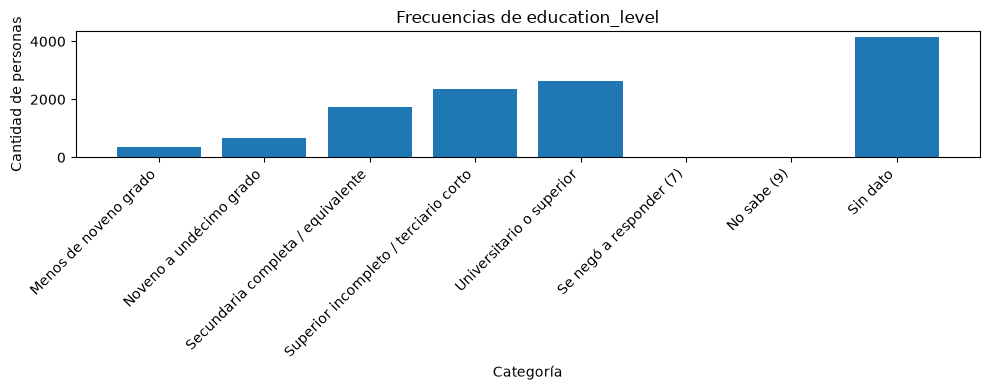

diabetes_diagnosed


,Frecuencia,Porcentaje del total
diabetes_diagnosed,,
Sí,1081,9.06
No,10371,86.91
Diagnóstico límite,284,2.38
Se negó a responder (7),0,0.00
No sabe (9),4,0.03
Sin dato,193,1.62


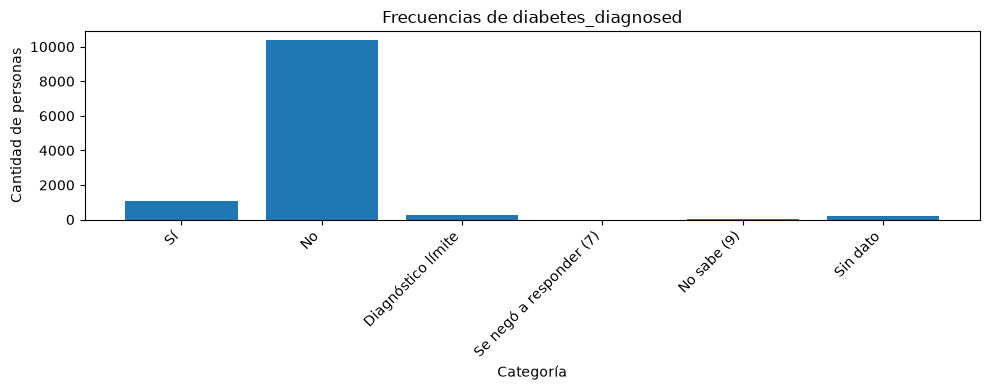

insulin_use


,Frecuencia,Porcentaje del total
insulin_use,,
Sí,344,2.88
No,737,6.18
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,10852,90.94


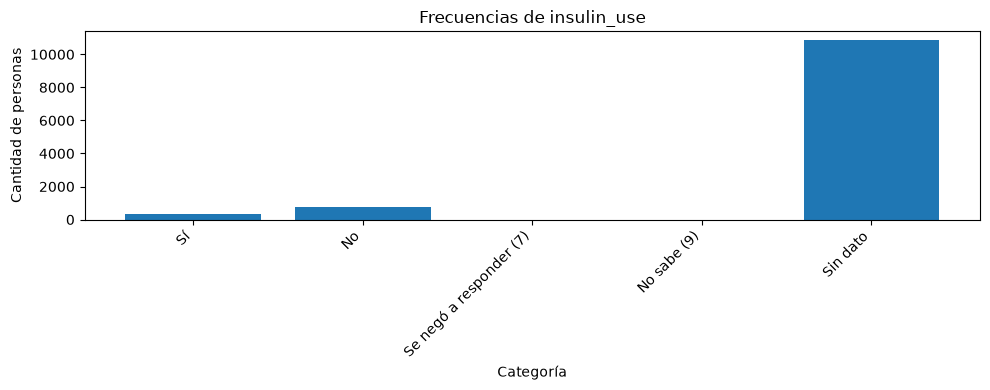

diabetes_pills


,Frecuencia,Porcentaje del total
diabetes_pills,,
Sí,885,7.42
No,1389,11.64
Se negó a responder (7),0,0.00
No sabe (9),7,0.06
Sin dato,9652,80.88


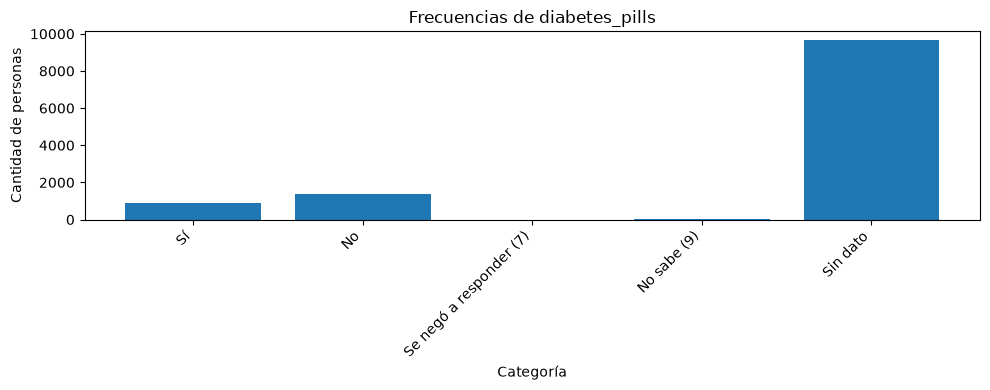

ever_smoked


,Frecuencia,Porcentaje del total
ever_smoked,,
Sí,3243,27.18
No,4878,40.88
Se negó a responder (7),7,0.06
No sabe (9),7,0.06
Sin dato,3798,31.83


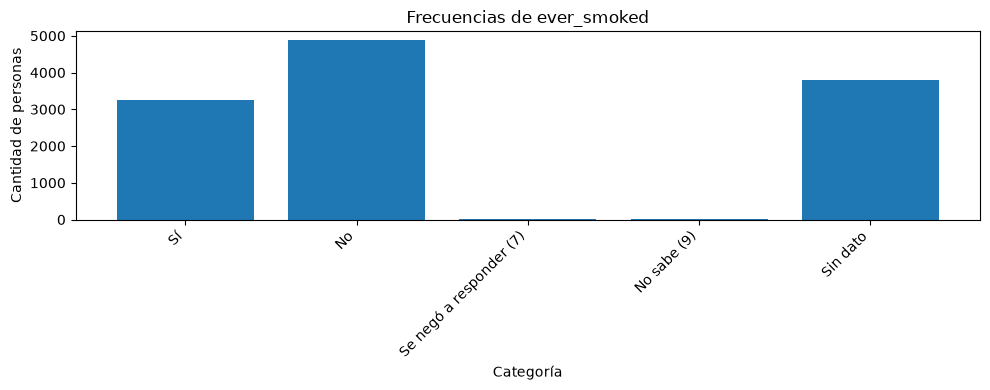

current_smoker


,Frecuencia,Porcentaje del total
current_smoker,,
Todos los días,952,7.98
Algunos días,238,1.99
Actualmente no fuma,2053,17.20
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,8690,72.82


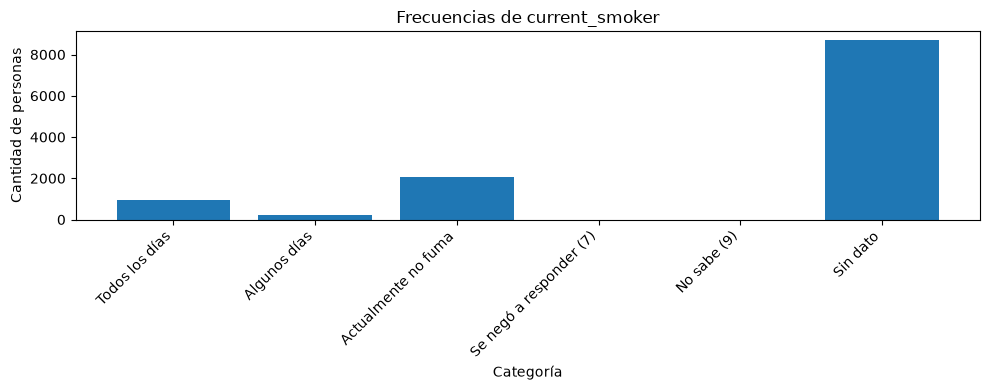

ckd_stage


,Frecuencia,Porcentaje del total
ckd_stage,,
No CKD,3592,30.10
Etapa 1,382,3.20
Etapa 2,1875,15.71
Etapa 3a,341,2.86
Etapa 3b,97,0.81
Etapa 4,28,0.23
Etapa 5,11,0.09
Etapa desconocida,5607,46.99
Sin dato,0,0.00


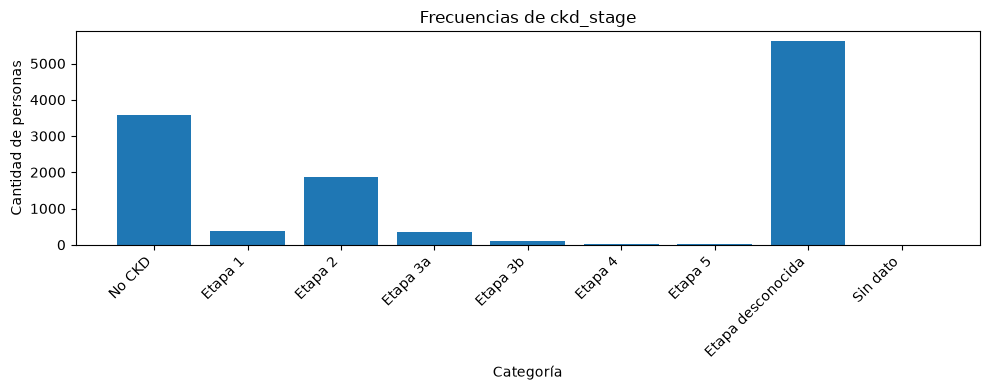

ckd_present


,Frecuencia,Porcentaje del total
ckd_present,,
Sin CKD según el archivo,3592,30.10
Con CKD según el archivo,2734,22.91
Sin dato,5607,46.99


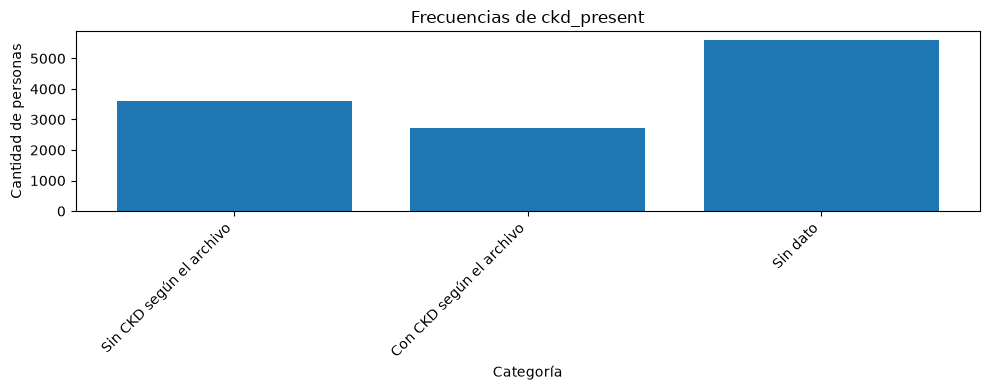

In [83]:
frecuencias_categoricas = {}

for columna, etiquetas in etiquetas_categorias.items():
    # Recuperamos los códigos de no respuesta que la conversión booleana unificó.
    if columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
        serie = df[columna].replace({
            1: "Sí", 2: "No",
            7: "Se negó a responder (7)", 9: "No sabe (9)"
        }).fillna("Sin dato")
        orden = ["Sí", "No", "Se negó a responder (7)", "No sabe (9)", "Sin dato"]
    else:
        serie = df_limpio[columna].astype("object").replace(etiquetas).fillna("Sin dato")
        orden = list(etiquetas.values()) + ["Sin dato"]

    # Conservamos también cualquier categoría que no figure en la metadata.
    serie = serie.astype(str)
    frecuencias = serie.value_counts()
    categorias_adicionales = [valor for valor in frecuencias.index if valor not in orden]
    frecuencias = frecuencias.reindex(orden + categorias_adicionales, fill_value=0)
    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje del total": (frecuencias / len(df_limpio) * 100).round(2)
    })
    frecuencias_categoricas[columna] = tabla
    print(columna)
    display(tabla)

    plt.figure(figsize=(10, 4))
    plt.bar(tabla.index, tabla["Frecuencia"])
    plt.title("Frecuencias de " + columna)
    plt.xlabel("Categoría")
    plt.ylabel("Cantidad de personas")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


### Resumen de las variables cuantitativas

`count` indica cuántos valores observados intervienen en cada resumen. Media, desvío estándar, mínimo, cuartiles, mediana y máximo se calculan sin los nulos; no se imputan valores. Los códigos de categorías y el identificador quedan fuera de estos cálculos.

Las unidades se consultan en la metadata: edad en años; peso en kg; altura en cm; BMI en kg/m²; presiones en mmHg; creatinina sérica, nitrógeno ureico, fósforo, calcio, ácido úrico y creatinina urinaria en mg/dL; albúmina sérica en g/dL; bicarbonato en mmol/L; albúmina urinaria en µg/mL; ACR en mg/g; eGFR en mL/min/1,73 m². La razón ingreso/pobreza no tiene unidad.


In [84]:
resumen_numericas = df_limpio[variables_numericas].describe().T
resumen_numericas["nulos"] = df_limpio[variables_numericas].isna().sum()
resumen_numericas["porcentaje_nulos"] = (
    df_limpio[variables_numericas].isna().mean() * 100
)
resumen_numericas.round(2)


,count,mean,std,min,25%,50%,75%,max,nulos,porcentaje_nulos
age,11933.0,38.317858,25.60199,0.0,13.0,37.0,62.0,80.0,0,0.00
poverty_income_ratio,9892.0,2.708174,1.670119,0.0,1.18,2.5,4.5,5.0,2041,17.10
bmi,8471.0,27.246665,8.137781,11.1,21.6,26.4,31.7,74.8,3462,29.01
weight_kg,8754.0,70.549037,30.389021,2.7,54.2,71.7,89.1,248.2,3179,26.64
height_cm,8499.0,159.664549,19.864943,79.1,154.4,163.6,172.1,200.7,3434,28.78
bp_systolic,7517.0,119.288546,18.561052,61.0,106.0,117.0,130.0,232.0,4416,37.01
bp_diastolic,7517.0,72.748038,11.895572,33.0,64.0,72.0,80.0,142.0,4416,37.01
serum_creatinine,6326.0,0.872828,0.385498,0.33,0.7,0.83,0.98,15.17,5607,46.99
blood_urea_nitrogen,6326.0,14.659817,5.754035,4.0,11.0,14.0,17.0,74.0,5607,46.99
albumin_serum,6366.0,4.099246,0.355161,2.2,3.9,4.1,4.3,5.5,5567,46.65


### Distribuciones de las variables cuantitativas

Los histogramas agrupan los valores observados en 30 intervalos. Los ejes son independientes: las alturas y los rangos no deben compararse directamente entre variables con distintas cantidades de datos o unidades. Los extremos se conservan.


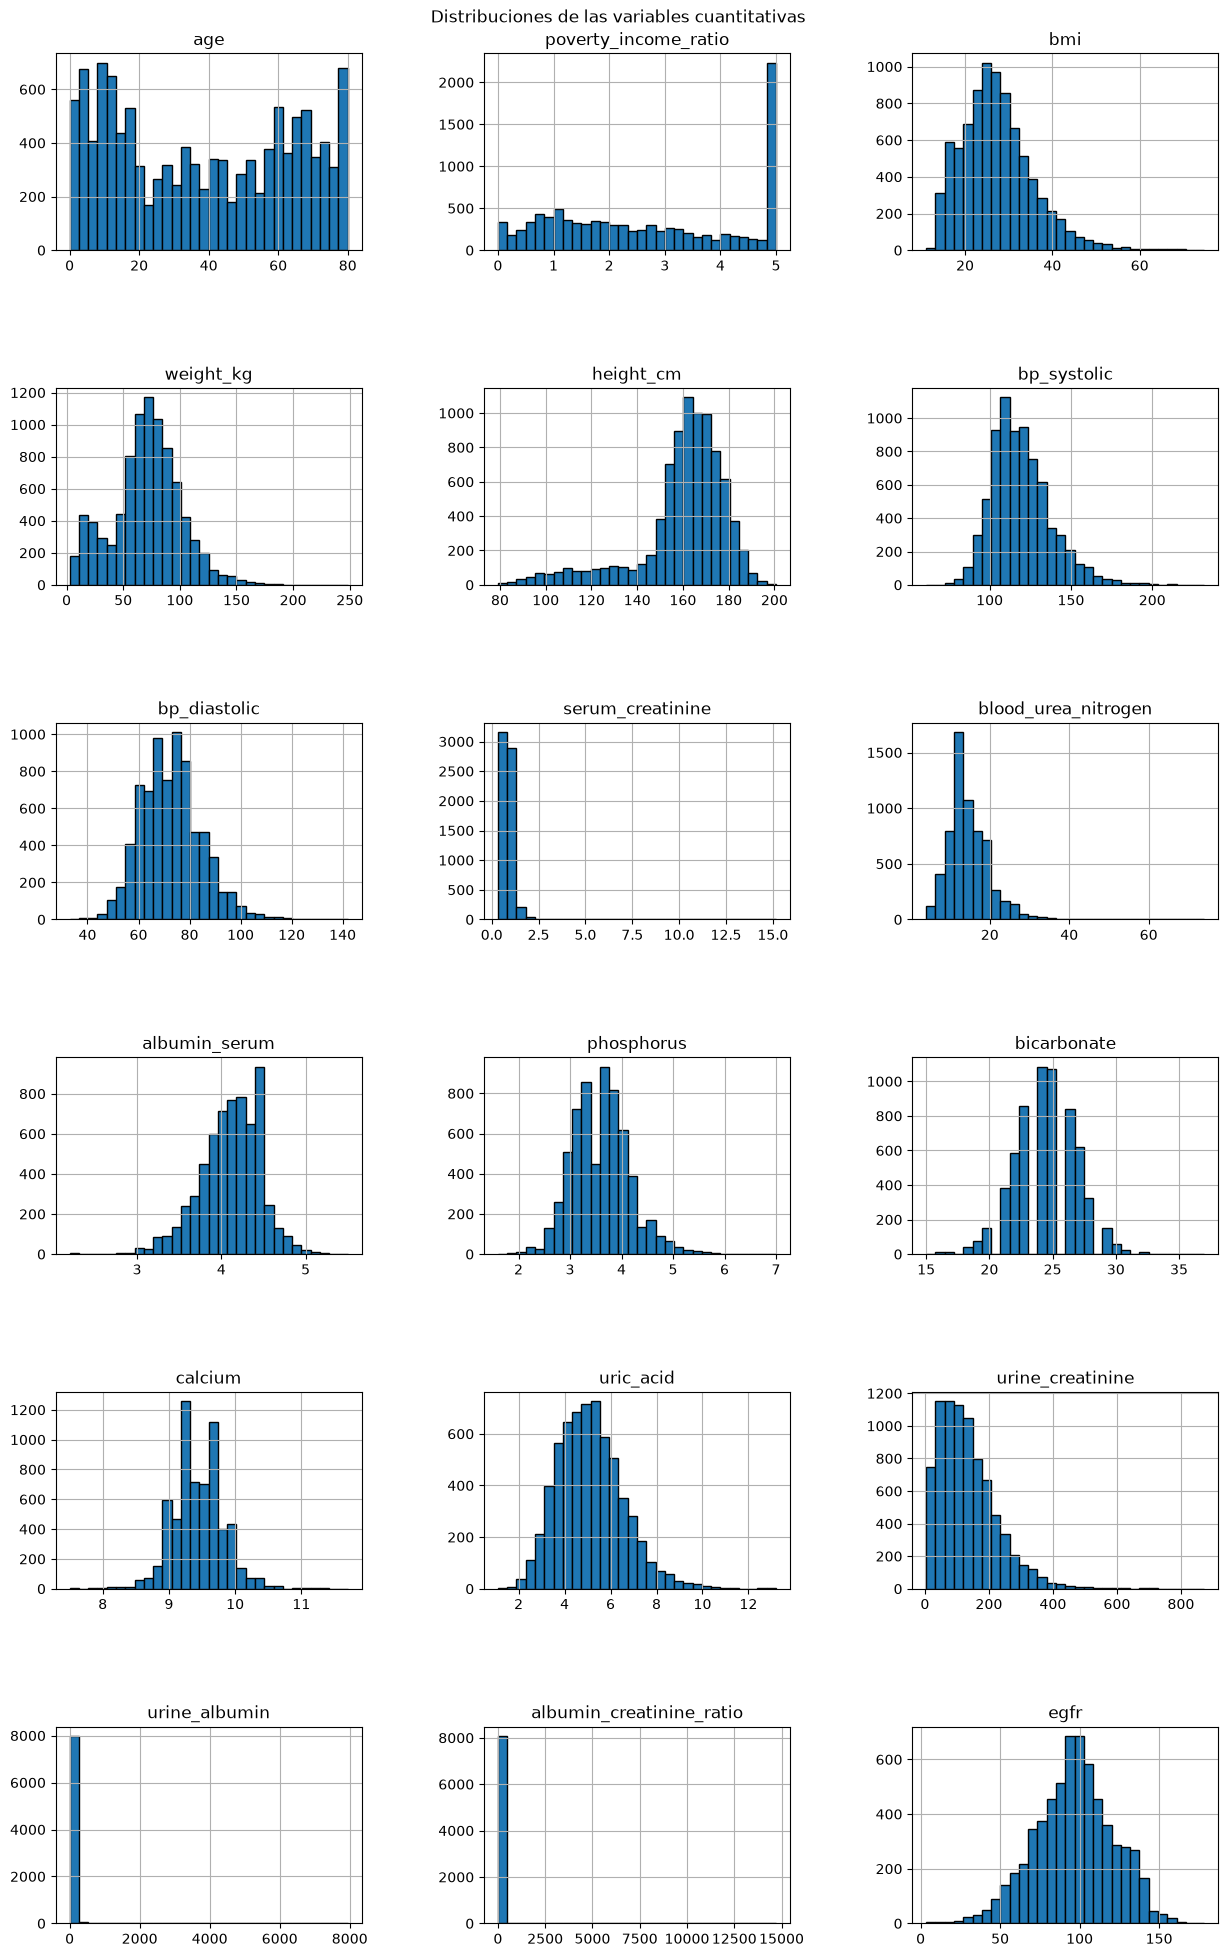

In [85]:
df_limpio[variables_numericas].hist(
    figsize=(15, 22), layout=(6, 3), bins=30, edgecolor="black"
)
plt.subplots_adjust(top=0.96, hspace=0.7, wspace=0.4)
plt.suptitle("Distribuciones de las variables cuantitativas")
plt.show()


### Histogramas con escala ajustada

En los histogramas generales, los valores altos de `urine_albumin`, `albumin_creatinine_ratio` y `serum_creatinine` comprimen la zona donde se concentra la mayor parte de los datos. Para observar mejor sus distribuciones, agregamos histogramas con rangos acotados.

Estos gráficos muestran únicamente los valores dentro de los rangos indicados. Los valores que quedan fuera de esos rangos permanecen en el dataset; el ajuste solo cambia la visualización.


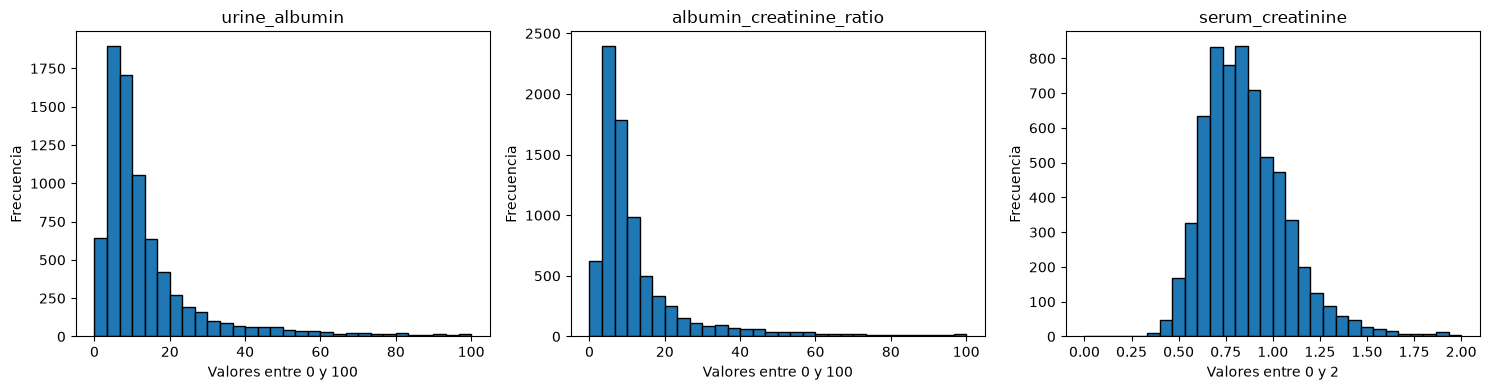

In [86]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for columna, limite, eje in zip(
    ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"],
    [100, 100, 2], ejes
):
    eje.hist(df_limpio[columna].dropna(), bins=30, range=(0, limite), edgecolor="black")
    eje.set_title(columna)
    eje.set_xlabel(f"Valores entre 0 y {limite}")
    eje.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### Medianas, dispersión y valores extremos

Cada diagrama de caja usa su propia escala y omite los nulos. La línea central representa la mediana y la caja contiene el 50% central. Los puntos fuera de los bigotes son posibles valores extremos según la regla de 1,5 veces el rango intercuartílico; no son errores confirmados y no se eliminan.


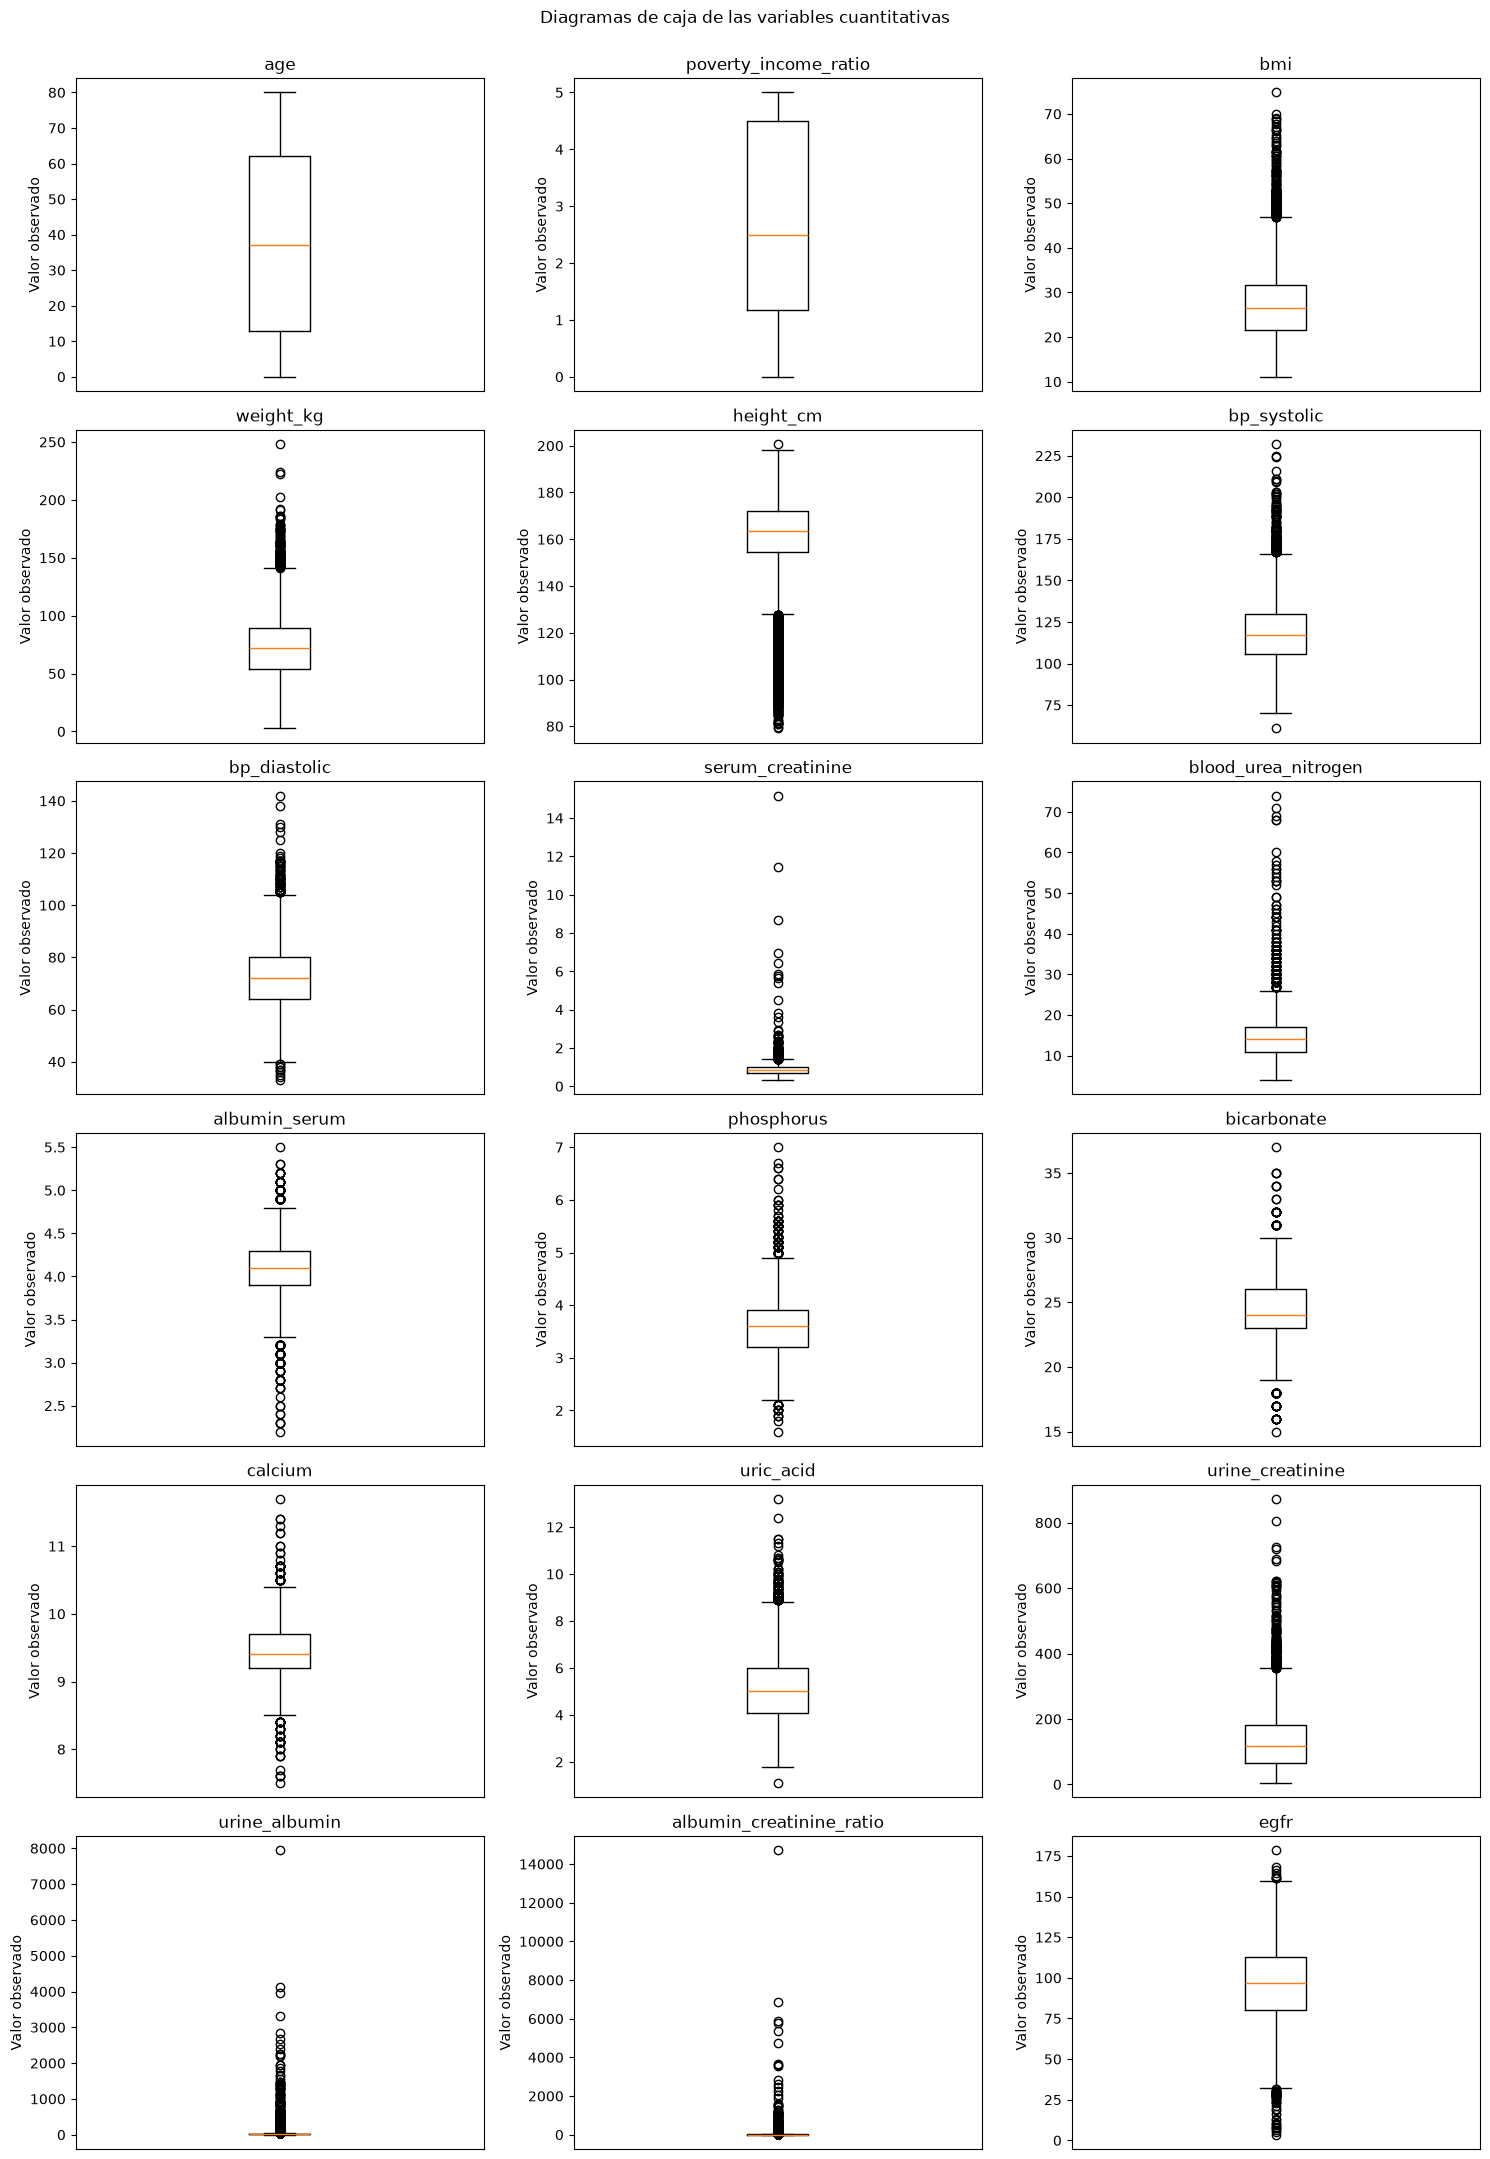

In [87]:
figura, ejes = plt.subplots(6, 3, figsize=(15, 22))

for columna, eje in zip(variables_numericas, ejes.flat):
    valores = df_limpio[columna].dropna().astype(float)
    eje.boxplot(valores)
    eje.set_title(columna)
    eje.set_xticks([])
    eje.set_ylabel("Valor observado")

figura.suptitle("Diagramas de caja de las variables cuantitativas")
figura.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


### Filas que contienen los máximos seleccionados

Mostramos todas las filas que contienen el máximo de `urine_albumin`, `albumin_creatinine_ratio` o `serum_creatinine`. Si varias filas comparten un máximo, se muestran todas. Una fila que coincide en más de una variable aparece una sola vez.

Esta consulta permite revisar los registros completos. `df` y `df_limpio` conservan todas sus filas.


In [88]:
variables_maximos = ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"]
filas_con_maximos = pd.Series(False, index=df_limpio.index)

for columna in variables_maximos:
    maximo = df_limpio[columna].max()
    print(f"Máximo de {columna}: {maximo}")
    filas_con_maximos = filas_con_maximos | (df_limpio[columna] == maximo).fillna(False)

print("Filas que contienen alguno de los máximos:", filas_con_maximos.sum())
display(df_limpio.loc[filas_con_maximos])


Máximo de urine_albumin: 7942.47
Máximo de albumin_creatinine_ratio: 14708.28
Máximo de serum_creatinine: 15.17
Filas que contienen alguno de los máximos: 1


,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
6251,50,Male,Non-Hispanic Asian,5,1.26,27.4,79.9,170.7,139.0,71.0,15.17,52.0,3.9,6.6,23.0,8.6,7.7,54.0,7942.47,14708.28,1,True,False,True,3,3.51,Stage 5 (Kidney Failure),1


# Hipotesis

### Planteo y analisis de la hipotesis Univariada

Hipotesis:En la población general examinada con función renal evaluable, la mediana de la relación albúmina-creatinina en orina (ACR) se mantiene significativamente por debajo del umbral clínico de daño renal 30 mg/g

Comenzamos tomando la variable sin nulos, y chequeando test de normalidad mediante shapiro-wilk

In [89]:
from scipy.stats import shapiro

acr = df_limpio["albumin_creatinine_ratio"].dropna()

stat, p = shapiro(acr)
print(f"Test de Shapiro-Wilk sobre ACR: Estadístico={stat:.3f}, p-valor={p:.3f}")



Test de Shapiro-Wilk sobre ACR: Estadístico=0.070, p-valor=0.000


/home/beto/Desktop/TPE_C_DATOS/.venv/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8153.
  res = hypotest_fun_out(*samples, **kwds)


En este caso vemos que los datos no son normales, como habiamos detallado antes hay una gran prescencia de outliers

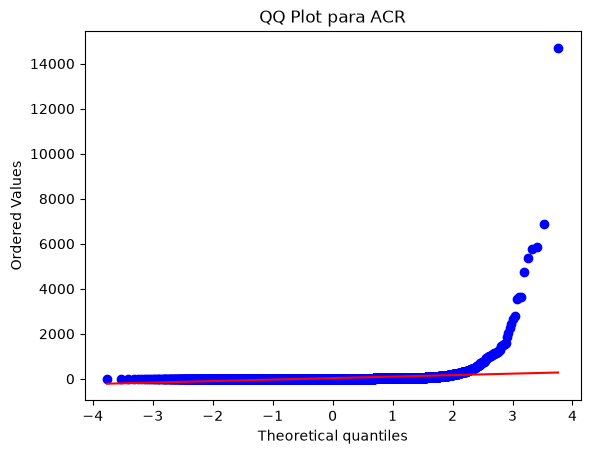

In [90]:
import matplotlib.pyplot as plt
import scipy.stats as stats

stats.probplot(acr, dist="norm", plot=plt)
plt.title("QQ Plot para ACR")
plt.show()

In [91]:
stat_wilcox, p_wilcox = stats.wilcoxon(acr - 30, alternative="less")

In [92]:
print(f"Mediana de ACR: {acr.median():.2f} mg/g | Media de ACR: {acr.mean():.2f} mg/g")
print(f"Test de Wilcoxon (mediana < 30): estadístico = {stat_wilcox:.2f}, p-valor = {p_wilcox:.4e}")

Mediana de ACR: 8.27 mg/g | Media de ACR: 33.36 mg/g
Test de Wilcoxon (mediana < 30): estadístico = 4790841.00, p-valor = 0.0000e+00


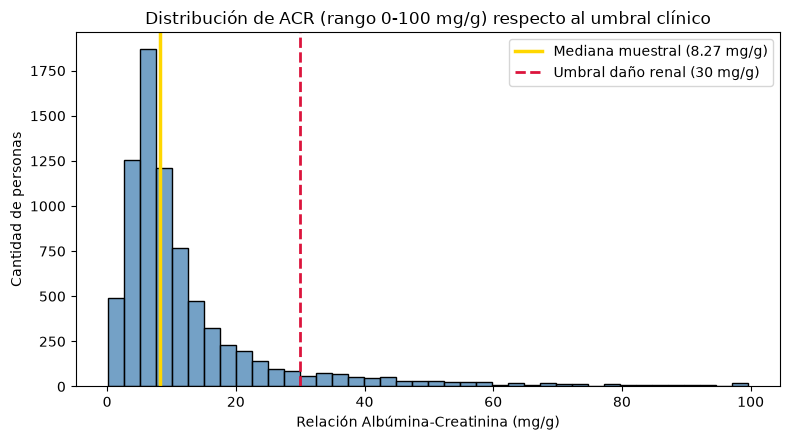

In [93]:
# 4. Visualización (Histograma acotado + líneas de referencia, estilo Práctico 5)
plt.figure(figsize=(8, 4.5))
sns.histplot(acr[acr <= 100], bins=40, color="steelblue", edgecolor="black")
plt.axvline(acr.median(), color="gold", linewidth=2.5, label=f"Mediana muestral ({acr.median():.2f} mg/g)")
plt.axvline(30, color="crimson", linestyle="--", linewidth=2, label="Umbral daño renal (30 mg/g)")
plt.title("Distribución de ACR (rango 0-100 mg/g) respecto al umbral clínico")
plt.xlabel("Relación Albúmina-Creatinina (mg/g)")
plt.ylabel("Cantidad de personas")
plt.legend()
plt.tight_layout()
plt.show()

Como vemos que el p-valor es muy menor a 0.05 podemos rechazar la H0, y confirma nuestra hipotesis.

### Planteo y Analisis de Hipotesis Bivariada

Hipotesis: La prevalencia de enfermedad renal crónica (ckd_present) no es independiente del diagnóstico de diabetes (diabetes_diagnosed), siendo significativamente superior en personas diagnosticadas con diabetes o prediabetes (diagnóstico límite). Elegimos la misma ya que nos interesa probar que la diabetes, es la principal causa de la ECR

H0: La presencia de ERC y el diagnóstico de diabetes son estadísticamente independientes.
H1: Existe asociación estadística entre el diagnóstico de diabetes y la presencia de ERC.

Para el test, analizamos que ambas variables son cualitataticas, codificadas. y como estamos chequeado independencia de 2 cualitativas debemos utilizar chi cuadrado mediante la comparacion de frecuencias obtenidas con frecuencias esperadas.

Para comenzar realizamos un fitrado de los codigos validos de de diabetes, los cuales eran: 1(si) 2(no) 3(diagnostico limite), quitamos los valores nulos de ckd_present, mapeamos los codigos a categorias legibles para que lo entendamos mejor.

In [94]:
#filtrado
df_renal = df_limpio.dropna(subset=["ckd_present"]).copy()
df_renal["ckd_present"] = df_renal["ckd_present"].astype(int)
df_diab = df_renal[df_renal["diabetes_diagnosed"].isin([1, 2, 3])].copy()


#utilizamos un diccionario para traducir los numeros a etiquetas y las guardamos en una nueva columna llamada diabetes_cat 
mapeo_diabetes = {1: "Sí", 2: "No", 3: "Diagnóstico límite"}
df_diab["diabetes_cat"] = df_diab["diabetes_diagnosed"].map(mapeo_diabetes)


#construimos la tabla de contigencia con pandas
tabla_contingencia = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"])

# aplicamos el chi-cuadrado a la tabla de contungencia armada, en chi2 guardamos el valor del estadistico, en p_val el pvalor, en dof los grados de libertad (que recordamos que se calculan como filas-1, col-1)
# y en ex queda la matriz de frecuencias esperadas
chi2, p_val_chi2, dof, ex = stats.chi2_contingency(tabla_contingencia)


# y volvemos a hacer un pd.crosstab para armar una segunda tabla pero con porcentajes sumados por fila para estandarizarlos
proporciones_diab = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"], normalize="index") * 100


print("Tabla de contingencia (frecuencias obtenidas):\n", tabla_contingencia)
print("\nPrevalencia por fila (%):\n", proporciones_diab.round(2))
print(f"\nChi-cuadrado: {chi2:.2f}, gl: {dof}, p-valor: {p_val_chi2:.4e}\n")

Tabla de contingencia (frecuencias obtenidas):
 ckd_present            0     1
diabetes_cat                  
Diagnóstico límite    99   104
No                  3228  2128
Sí                   264   502

Prevalencia por fila (%):
 ckd_present             0      1
diabetes_cat                    
Diagnóstico límite  48.77  51.23
No                  60.27  39.73
Sí                  34.46  65.54

Chi-cuadrado: 187.31, gl: 2, p-valor: 2.1233e-41



como podemos ver el pvalor es terriblemente menor a 0.05, por lo que podemos rechazar la hipotesis nula de independencia y asegurar una depencia entre la prevalencia de enfermedad renal cronica y el diagnostico de diabetes

### Planteo y Analisis de Hipotesis Multivariada

Hipotesis: En los participantes adultos analizados, los perfiles definidos conjuntamente por edad, indice de masa corporal y presion arterial presentan distintas proporciones de CKD. Se espera que el perfil caracterizado por mayor edad y presion sistolica presente una proporcion mayor.

Para resolver esta hipotesis multivariada planteamos los siguientes pasos:
1. Filtrado y analisis de correlacion : Nos quedamos con los participantes adultos > 18 sin nulos y vemos la matriz de correlacion entre edad, BMI, presion sistolica y presion diastolica para ver si alguna de las variable es redundante antes de armar los perfiles
2. Estandarizamos y Clustering con K-Means: Como estamos buscando descubrir perfiles definidos conjuntamente por variables cuantitativas sin usar la variable respuesta, estandarizamos las variables con StandardScaler y aplicamos K-Means evaluando distintos valores de k mediante el grafico del codo y el Coeficiente de Silueta.
3. Caracterizacion de los perfiles y proyeccion en PCA biplot: Describimos que caracteriza a cada perfil en sus unidades originales (mediante tablas y boxplots) y proyectamos los perfiles en 2 dimensiones usando PCA y Biplot para ver si los agrupamientos tienen sentido en el espacio reducido
4. Validacion estadistica de la hipotesis: Una vez definidos los perfiles, cruzamos el perfil asignado a cada adulto con ckd_present en una tabla de contingencia y aplicamos el Test Chi-cuadrado de independencia/homogeneidad para probar si las proporciones de CKD difieren significativamente entre los perfiles y si el perfil de mayor edad y presion sistolica tiene la mayor proporcion. 

Filtramos los participantes adultos (18 años o mas) que tengan datos completos en edad, BMI, presion arterial y diagnostico de CKD, y calculamos la matriz de correlacion entre las variables cuantitativas.

Cantidad de participantes adultos con datos completos: 5438


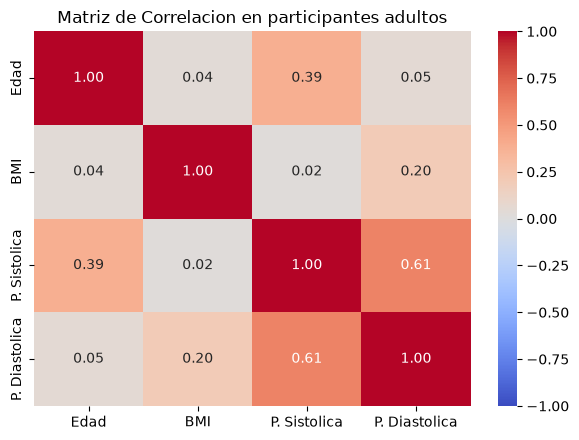

In [95]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# filtramos participantes adultos (age >= 18) sin nulos en las variables de interes
vars_iniciales = ["age", "bmi", "bp_systolic", "bp_diastolic"]
df_adultos = df_limpio[df_limpio["age"] >= 18].dropna(subset=vars_iniciales + ["ckd_present"]).copy()
df_adultos["ckd_present"] = df_adultos["ckd_present"].astype(int)

print("Cantidad de participantes adultos con datos completos:", len(df_adultos))

# calculamos y graficamos la matriz de correlacion de las variables cuantitativas
corr_adultos = df_adultos[vars_iniciales].astype(float).corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    corr_adultos, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
    xticklabels=["Edad", "BMI", "P. Sistolica", "P. Diastolica"],
    yticklabels=["Edad", "BMI", "P. Sistolica", "P. Diastolica"]
)
plt.title("Matriz de Correlacion en participantes adultos")
plt.tight_layout()
plt.show()

en la matriz de correlacion vemos que la Presion Sistolica y la Presion Diastolica tienen una correlacion alta (0.61), y ademas la Sistolica es la que se relaciona con la Edad (0.39). En K-Means se calcula la distancia euclidea entre los puntos, por lo que si dejamos dos variables de presion muy correlacionadas estariamos dandole el doble de peso a la presion arterial frente a la edad y el BMI. entonces nos quedamos con las 3 variables representativas de cada dimension fisica: age (Edad), bmi (Indice de Masa Corporal) y bp_systolic (Presion Sistolica).

Estandarizamos estas 3 variables con StandardScaler, antes de K-Means para que la presion y la edad no dominen por tener numeros mas grandes que el BMI, y probamos valores de k entre 2 y 6 analizando la Inercia (metodo del codo) y el Coeficiente de Silueta. 

,k,Inercia (WSS),Silueta media
0,2,11146.6,0.307
1,3,8398.9,0.318
2,4,6620.4,0.300
3,5,5937.0,0.285
4,6,5365.6,0.261


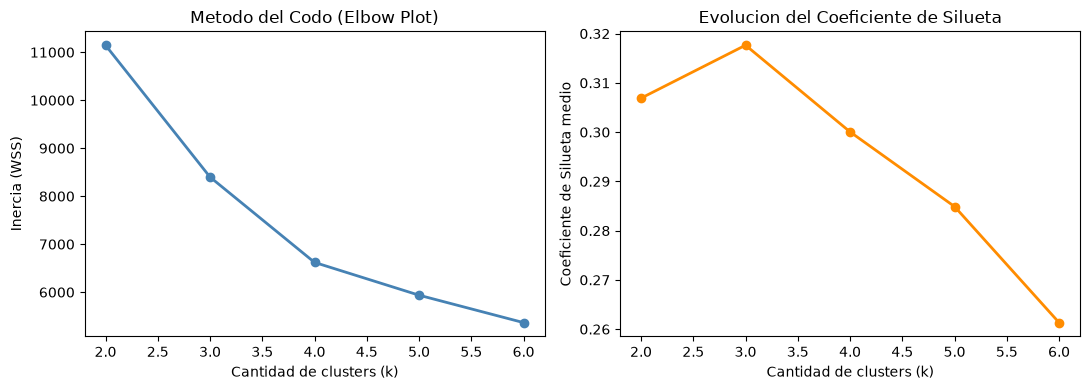

In [96]:
vars_perfil = ["age", "bmi", "bp_systolic"]
nombres_perfil = ["Edad", "BMI", "Presion Sistolica"]

X_adultos = df_adultos[vars_perfil].astype(float)

# estandarizamos las variables para que tengan media 0 y desvio 1
scaler_cluster = StandardScaler()
X_adultos_stand = scaler_cluster.fit_transform(X_adultos)

# probamos K-Means con k de 2 a 6 guardando la inercia y la silueta media
valores_k = range(2, 7)
inercias = []
siluetas = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=10, n_init=10)
    etiquetas = km.fit_predict(X_adultos_stand)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_adultos_stand, etiquetas))

tabla_k = pd.DataFrame({
    "k": list(valores_k),
    "Inercia (WSS)": np.round(inercias, 1),
    "Silueta media": np.round(siluetas, 3)
})
display(tabla_k)

# graficamos el Elbow plot y el Coeficiente de Silueta
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(valores_k, inercias, marker="o", color="steelblue", linewidth=2)
ejes[0].set_xlabel("Cantidad de clusters (k)")
ejes[0].set_ylabel("Inercia (WSS)")
ejes[0].set_title("Metodo del Codo (Elbow Plot)")

ejes[1].plot(valores_k, siluetas, marker="o", color="darkorange", linewidth=2)
ejes[1].set_xlabel("Cantidad de clusters (k)")
ejes[1].set_ylabel("Coeficiente de Silueta medio")
ejes[1].set_title("Evolucion del Coeficiente de Silueta")

plt.tight_layout()
plt.show()

La inercia siempre baja a medida que aumentamos k, pero buscamos un punto de inflexion (codo) y al mismo tiempo buscamos maximizar el Coeficiente de Silueta. En la tabla y el grafico se ve que k = 3 alcanza el maximo Coeficiente de Silueta y marca un buen compromiso de reduccion de inercia (8398.9), por lo que elegimos k = 3 perfiles.

Ajustamos K-Means con k = 3, analizamos que caracteriza a cada uno de los 3 perfiles en sus unidades originales (mediante tablas de medias/medianas y boxplots) y los proyectamos en 2 dimensiones usando PCA y Biplot.

Caracterizacion de los 3 perfiles en sus unidades originales:


age                 bmi         \
                                           count   mean median count   mean   
perfil_nombre                                                                 
Perfil 0: Mayor edad y P. Sistolica alta    2382  66.85   67.0  2382  27.69   
Perfil 1: Edad media y BMI alto (Obesidad)  1130   51.5   53.0  1130  39.82   
Perfil 2: Jovenes con presion y BMI bajos   1926  35.85   35.0  1926  25.87   

                                                  bp_systolic                 
                                           median       count    mean median  
perfil_nombre                                                                 
Perfil 0: Mayor edad y P. Sistolica alta     27.6        2382  133.34  131.0  
Perfil 1: Edad media y BMI alto (Obesidad)   38.6        1130  117.76  117.0  
Perfil 2: Jovenes con presion y BMI bajos    25.7        1926  111.32  111.0

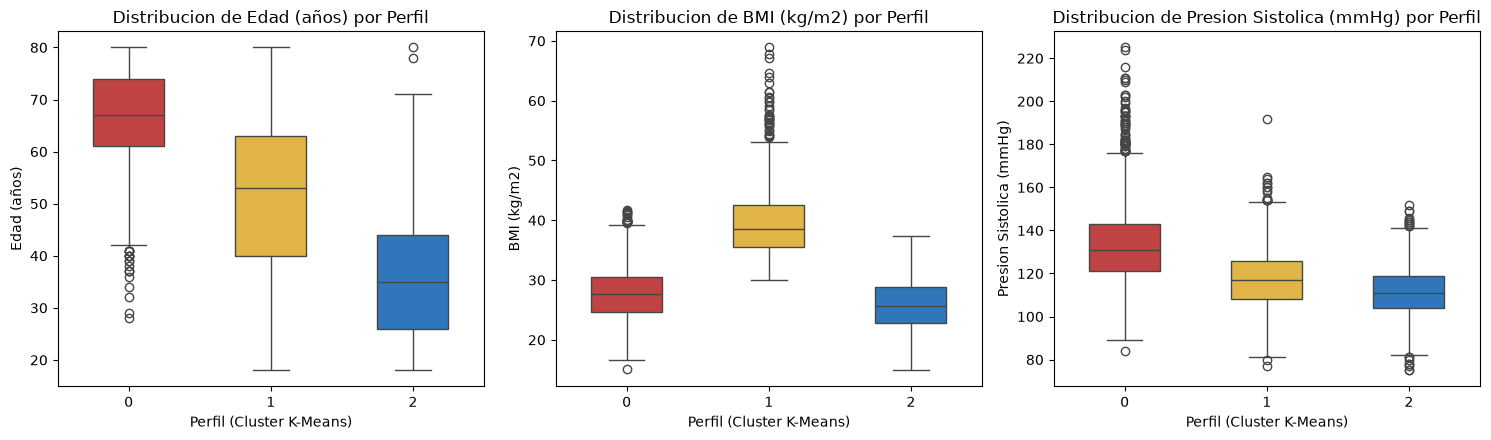

In [ ]:
# ajustamos K-Means con el k = 3 seleccionado
kmeans_final = KMeans(n_clusters=3, random_state=10, n_init=10)
df_adultos["cluster"] = kmeans_final.fit_predict(X_adultos_stand)

# le ponemos nombres descriptivos a cada perfil segun sus valores medios para que se entienda mejor
mapeo_perfiles = {
    0: "Perfil 0: Mayor edad y P. Sistolica alta",
    1: "Perfil 1: Edad media y BMI alto (Obesidad)",
    2: "Perfil 2: Jovenes con presion y BMI bajos"
}
df_adultos["perfil_nombre"] = df_adultos["cluster"].map(mapeo_perfiles)

resumen_perfiles = df_adultos.groupby("perfil_nombre")[vars_perfil].agg(["count", "mean", "median"]).round(2)
print("Caracterizacion de los 3 perfiles en sus unidades originales:")
display(resumen_perfiles)

# graficamos los boxplots de las 3 variables por perfil en unidades originales 
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
orden_perfiles = [
    "Perfil 0: Mayor edad y P. Sistolica alta",
    "Perfil 1: Edad media y BMI alto (Obesidad)",
    "Perfil 2: Jovenes con presion y BMI bajos"
]
colores_perf = ["#d32f2f", "#fbc02d", "#1976d2"]

for ax, col, titulo in zip(ejes, vars_perfil, ["Edad (años)", "BMI (kg/m2)", "Presion Sistolica (mmHg)"]):
    sns.boxplot(
        data=df_adultos, x="cluster", y=col, hue="cluster", ax=ax,
        palette=colores_perf, width=0.5, legend=False
    )
    ax.set_title(f"Distribucion de {titulo} por Perfil")
    ax.set_xlabel("Perfil (Cluster K-Means)")
    ax.set_ylabel(titulo)

plt.tight_layout()
plt.show()

Varianza explicada por PC1: 46.4% | PC2: 33.2% | Acumulada (2D): 79.6%


,Edad,BMI,Presion Sistolica
PC1,0.704,0.103,0.702
PC2,-0.052,0.994,-0.094


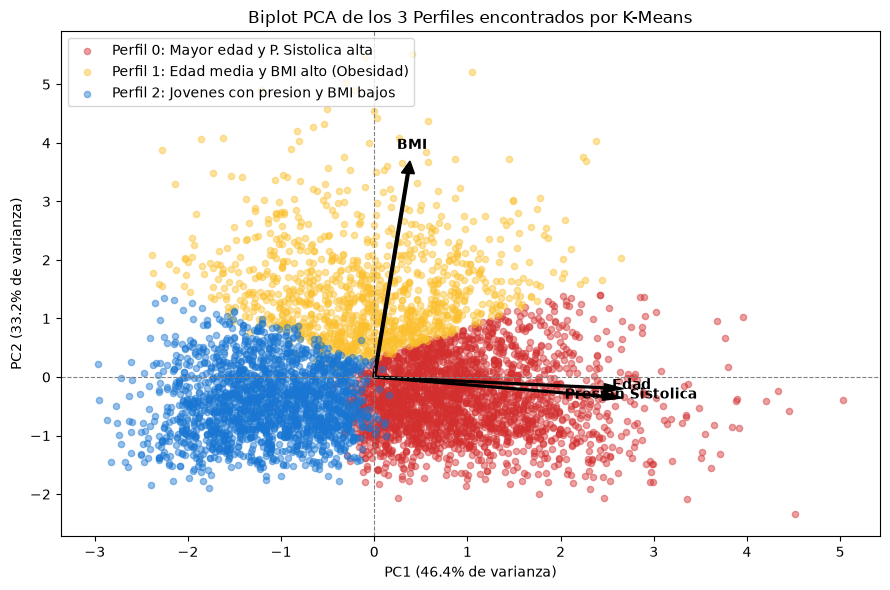

In [ ]:
# representamos los 3 perfiles en 2 dimensiones usando PCA y Biplot 
pca_perfiles = PCA()
coords_pca = pca_perfiles.fit_transform(X_adultos_stand)
var_exp_perf = pca_perfiles.explained_variance_ratio_

print(f"Varianza explicada por PC1: {var_exp_perf[0]*100:.1f}% | PC2: {var_exp_perf[1]*100:.1f}% | Acumulada (2D): {(var_exp_perf[0]+var_exp_perf[1])*100:.1f}%")

cargas_perf = pd.DataFrame(
    pca_perfiles.components_[:2],
    columns=nombres_perfil,
    index=["PC1", "PC2"]
)
display(cargas_perf.round(3))

plt.figure(figsize=(9, 6))
for cluster_id, color, etiqueta in zip([0, 1, 2], colores_perf, orden_perfiles):
    mask = (df_adultos["cluster"] == cluster_id).values
    plt.scatter(
        coords_pca[mask, 0], coords_pca[mask, 1],
        c=color, label=etiqueta, alpha=0.45, s=20
    )

# dibujamos los vectores de las variables originales sobre el plano del PCA
escala = 3.5
for i, nombre in enumerate(nombres_perfil):
    dx = pca_perfiles.components_[0, i] * escala
    dy = pca_perfiles.components_[1, i] * escala
    plt.arrow(0, 0, dx, dy, color="black", width=0.03, head_width=0.14)
    plt.text(dx * 1.12, dy * 1.12, nombre, color="black", fontsize=10, fontweight="bold", ha="center")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel(f"PC1 ({var_exp_perf[0]*100:.1f}% de varianza)")
plt.ylabel(f"PC2 ({var_exp_perf[1]*100:.1f}% de varianza)")
plt.title("Biplot PCA de los 3 Perfiles encontrados por K-Means")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

El Biplot del PCA explica el 79.6% de la varianza total con solo 2 componentes (46.4% la PC1 y 33.2% la PC2) y permite ver con total claridad por que los 3 agrupamientos tienen sentido:
- La PC1 combina con igual peso positivo la Edad (0.704) y la Presion Sistolica (0.702), separando hacia la derecha al Perfil 0 (rojo: adultos mayores con una edad mediana de 67 años y presion sistolica mediana de 131 mmHg) y hacia la izquierda al Perfil 2 (azul: adultos jovenes con edad mediana de 35 años y presion sistolica mediana de 111 mmHg).
- La PC2 esta dominada casi al 100% por el BMI (0.994), separando hacia arriba al Perfil 1 (amarillo: adultos de mediana edad con un BMI mediano de 38.6 kg/m2).

Recordando que la variable ckd_present no se uso en ningun momento para construir los clusters, ahora cruzamos los 3 perfiles obtenidos contra ckd_present mediante una tabla de contingencia y aplicamos el Test Chi-cuadrado de independencia/homogeneidad:
- H0: La proporcion de casos de CKD es igual en los tres perfiles definidos por edad, BMI y presion arterial (independencia entre el perfil y la presencia de CKD).
- H1: Los perfiles presentan distintas proporciones de CKD (siendo mayor en el perfil de mayor edad y presion sistolica).

In [ ]:
# construimos la tabla de contingencia entre los perfiles y ckd_present
tabla_cont_perfiles = pd.crosstab(df_adultos["perfil_nombre"], df_adultos["ckd_present"])
tabla_prop_perfiles = pd.crosstab(df_adultos["perfil_nombre"], df_adultos["ckd_present"], normalize="index") * 100

print("Tabla de contingencia (Frecuencias observadas por perfil):")
display(tabla_cont_perfiles)

print("Proporcion de CKD dentro de cada perfil (% por fila):")
display(tabla_prop_perfiles.round(2))

# aplicamos el Test Chi-cuadrado
chi2_perf, p_val_perf, dof_perf, esp_perf = stats.chi2_contingency(tabla_cont_perfiles)
print(f"Resultado del Test Chi-cuadrado: Chi2 = {chi2_perf:.2f}, gl = {dof_perf}, p-valor = {p_val_perf:.4e}")

# graficamos la proporcion de CKD en cada perfil
plt.figure(figsize=(8.5, 4.5))
etiquetas_barras = [
    "Perfil 0 (Mayor edad y P. Sistolica)",
    "Perfil 1 (Edad media y BMI alto)",
    "Perfil 2 (Jovenes, menor P. y BMI)"
]
barras_perf = plt.bar(
    etiquetas_barras,
    tabla_prop_perfiles[1].values,
    color=colores_perf, edgecolor="black", width=0.55
)

for b in barras_perf:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 1.5, f"{h:.2f}%", ha="center", fontweight="bold")

plt.ylabel("Prevalencia de CKD (%)")
plt.title("Proporcion de Enfermedad Renal Cronica (CKD) segun Perfil Multivariado")
plt.ylim(0, 80)
plt.tight_layout()
plt.show()

Conclusion:
Los resultados confirman  nuestra hipotesis. En primer lugar, el Test Chi-cuadrado arroja un estadistico Chi2 = 992.54 con 2 grados de libertad y un p-valor = 2.98e-216 (muchisimo menor a 0.05), por lo que rechazamos la hipotesis nula (H0) y demostramos que los perfiles definidos conjuntamente por edad, BMI y presion arterial presentan proporciones de CKD significativamente distintas.

En segundo lugar, al comparar los porcentajes entre los grupos descubiertos por K-Means, el Perfil 0 (caracterizado por la mayor edad con mediana de 67 años y la mayor presion sistolica con mediana de 131 mmHg) presenta una proporcion de CKD del 68.77%, superando ampliamente al Perfil 1 de mediana edad y alto BMI (45.58%) y triplicando al Perfil 2 de adultos jovenes con presion y BMI mas bajos (20.61%).

### Analisis de hipotesis univariada planteada por la catedra 

hipotesis: La mayoría de los casos de CKF identificados corresponde a blancos
no-hispánicos.

como principal analisis podemos ver que la hipotesis planteada por la catedra corresponde a un analisis bivariado, si bien poseemos dos columnas la columna CKD present nos sirve solamente para filtrar.

H0: Los blancos no-hispánicos no son mayoría (su proporción es del 50% o menos, es decir, están en igualdad o minoría respecto al resto de las etnias combinadas).

H1: Los blancos no-hispánicos sí son mayoría (su proporción es mayor al 50%).


Total de casos de CKD identificados (n): 2734



,Frecuencia Observada,Porcentaje (%)
ethnicity,,
Non-Hispanic White,1741,63.68
Non-Hispanic Black,377,13.79
Other Hispanic,235,8.60
Other/Multiracial,169,6.18
Mexican American,118,4.32
Non-Hispanic Asian,94,3.44



Proporción muestral de Blancos no-hispánicos (p̂): 0.6368 (63.68%)
Frecuencias observadas [Blancos NH, Resto]: [np.int64(1741), np.int64(993)] | Esperadas (50/50): [1367.0, 1367.0]
Test Chi-cuadrado de bondad de ajuste: Chi2 = 204.6467, p-valor = 2.0225e-46


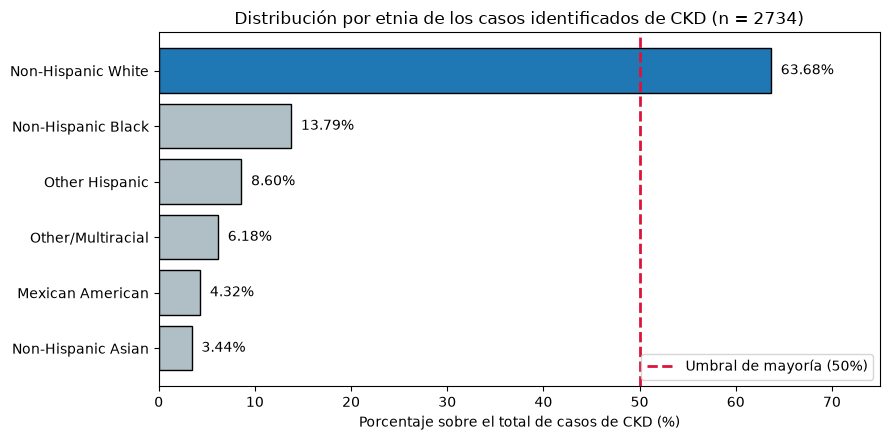

In [ ]:
# filtramos los casos con CKD
df_ckd = df_limpio[df_limpio["ckd_present"] == 1].dropna(subset=["ethnicity"]).copy()

# con los datos de los de ckd, construimos la tabla de frecuencias absolutas y realtivas, con value conts contamos cuantos pacientes pertenecen a cada etinia y obtenemos las absolutas, y cuando lo normalizamos obtenemos la relativas
n_ckd = len(df_ckd)
frec_abs = df_ckd["ethnicity"].value_counts()
frec_rel = (df_ckd["ethnicity"].value_counts(normalize=True) * 100).round(2)

tabla_etnias_ckd = pd.DataFrame({
    "Frecuencia Observada": frec_abs,
    "Porcentaje (%)": frec_rel
})
print(f"Total de casos de CKD identificados: {n_ckd}\n")
display(tabla_etnias_ckd)

# 3. Aca tenemos los datos para el contraste de una proporcion, blancos no-hispanicos contra el resto, tambien calculamos la poblacion muestral observada y establecemos el umbral de mayoria en 50%
k_blancos = frec_abs["Non-Hispanic White"]
k_resto = n_ckd - k_blancos
p_hat = k_blancos / n_ckd
p_0 = 0.50  


# Aplicamps el Test Chi-cuadrado de bondad de ajuste (frecuencias observadas vs esperadas 50/50), multiplicamos la cantidad por el umbral que decidimos 50% y utilizamos ese para las esperdas
frec_obs_bin = [k_blancos, k_resto]
frec_esp_bin = [n_ckd * p_0, n_ckd * (1 - p_0)]
chi2_gof, p_valor_chi2 = stats.chisquare(f_obs=frec_obs_bin, f_exp=frec_esp_bin)

print(f"\nProporción muestral de Blancos no-hispánicos (p̂): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Frecuencias observadas [Blancos NH, Resto]: {frec_obs_bin} | Esperadas (50/50): {frec_esp_bin}")

print(f"Test Chi-cuadrado de bondad de ajuste: Chi2 = {chi2_gof:.4f}, p-valor = {p_valor_chi2:.4e}")


plt.figure(figsize=(9, 4.5))
colores = ["#1f77b4" if etnia == "Non-Hispanic White" else "#b0bec5" for etnia in frec_rel.index]
barras = plt.barh(frec_rel.index[::-1], frec_rel.values[::-1], color=colores[::-1], edgecolor="black")

plt.axvline(50, color="crimson", linestyle="--", linewidth=2, label="Umbral de mayoría (50%)")
plt.xlabel("Porcentaje sobre el total de casos de CKD (%)")
plt.title("Distribución por etnia de los casos identificados de CKD (n = 2734)")
plt.xlim(0, 75)

for barra in barras:
    ancho = barra.get_width()
    plt.text(ancho + 1, barra.get_y() + barra.get_height()/2, f"{ancho:.2f}%", va="center", fontsize=10)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

A partir del análisis realizado, se observó que el 63,68 % de los casos identificados de CKD con etnia conocida corresponde a personas blancas no hispánicas, superando el umbral del 50 % establecido para considerar una mayoría.

Para determinar si esta diferencia es estadísticamente significativa, se aplicó un test de hipótesis Chi-cuadrado de bondad de ajuste con un nivel de significancia de α = 0,05.

Dado que el p-valor obtenido es menor a 0,05, se rechaza la hipótesis nula

Por lo tanto, existe evidencia estadística suficiente para respaldar la hipótesis de investigación, concluyendo que la proporción de personas blancas no hispánicas entre los casos identificados de CKD es significativamente mayor al 50 %.

### Analisis de la hipotesis bivariada de independencia planteada por la catedra.

El analisis general que hicimos para encarar el problema planteo dos preguntas, como resolvemos el caso de tener la presion dividad en dos variables, y tambien que es una comparacion entre cualitativa y cuantitativa.
Retrocediendo a los primeros conceptos de la catedra decidimos intentar una categorizacion de la variable continua para poder tratarla como cualitativa, asi de la misma forma podria tambien colapsar las dos variables en una misma. en un analisis del dominio dimos con el dato de que:

En medicina (y en las guías de la OMS y la Asociación Americana del Corazón / AHA), una persona se diagnostica con Hipertensión considerando ambas presiones de forma combinada:

Se considera hipertenso si tiene Sistólica ≥ 130 mmHg o Diastolica ≥ 80 mmHg.

Teniendo este dato decidimos crear una cuantitativa nominal hipertension que diferencia entre ("hippertenso" y "normal")

De esta forma podriamos realizar una tabla de contingencia 2x2 para luego pasar a un test Chi-Cuadrado de independecia con:

H0: La presencia de enfermedad renal cronica y la condicion de hipertension arterial son estadisticamente independientes.

H1: Existe asociacion estadistica entre la condicion de hipertension arterial y la presencia de enfermedad renal cronica (no son independientes, siendo la hipertension un factor de riesgo).


Luego utilizamos cuatro variables 

Hipertenso con CKD
Hipertenso sin CKD
Normotenso sin CKD
Normotenso con CKD

para poder hacer un analisis de las siguientes dos metricas que consideramos interesantes 

RR (Riesgo relativo): es el cociente entre la probabilidad de tener CKD si sos hipertenso (hipertenso con CKD /(hipertenso con CKD + hipertenso sin CKD)) sobre la probabilidad si sos normotenso(Normotenso con CKD/ (Normotenso con CKD + Normotenso sin CKD))

y odds ratio: que es la razon de ventajas cruzadas ((Hipertenso con CKD x Normotenso sin CKD)/ (Hipertenso sin CKD x Normotenso con CKD))




Tabla de contingencia (Frecuencias observadas):


CKD Presente,0,1
Condición de Presión,,
Hipertenso,1017,1338
Normotenso,2453,1325



Prevalencia por condición (% por fila):


ckd_present,0,1
hipertension,,
Hipertenso,43.18,56.82
Normotenso,64.93,35.07



Resultados del Test Chi-cuadrado:
Estadístico Chi2: 278.30
Grados de libertad: 1
p-valor: 1.7589e-62

Medidas de riesgo:
Riesgo Relativo (RR): 1.62
Odds Ratio (OR): 2.44


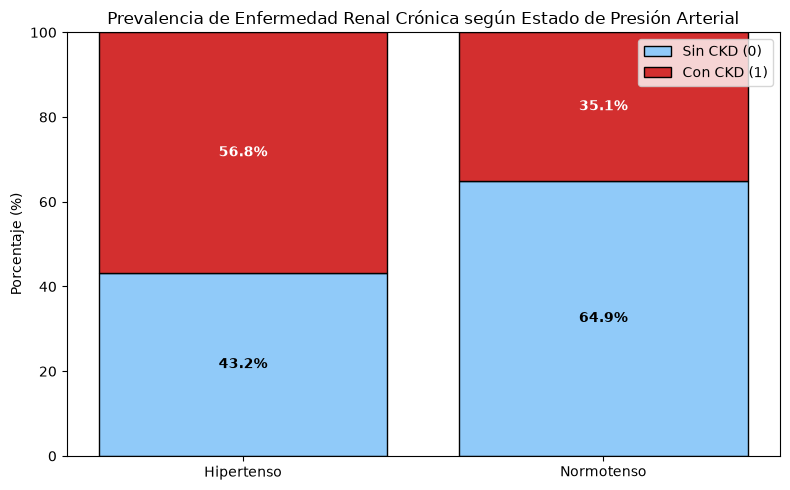

In [ ]:
# Filtramos las observaciones con datos completos en las variables de interés
df_presion = df_limpio.dropna(subset=["ckd_present", "bp_systolic", "bp_diastolic"]).copy()
df_presion["ckd_present"] = df_presion["ckd_present"].astype(int)


# pasamos a la creación de la variable categórica según lo explicado, usamos el np.where que funciona como un IF-ELSE si la condicion se cumple asigna el primer string sino el segundo
es_hipertenso = (df_presion["bp_systolic"] >= 130) | (df_presion["bp_diastolic"] >= 80)
df_presion["hipertension"] = np.where(es_hipertenso, "Hipertenso", "Normotenso")


# construimos las tablas de contingencia
# Frecuencias observadas 
tabla_contingencia = pd.crosstab(
    df_presion["hipertension"],
    df_presion["ckd_present"],
    rownames=["Condición de Presión"],
    colnames=["CKD Presente"]
)
# Porcentajes calculados por fila 
tabla_porcentajes = pd.crosstab(
    df_presion["hipertension"],
    df_presion["ckd_present"],
    normalize="index"
) * 100



print("Tabla de contingencia (Frecuencias observadas):")
display(tabla_contingencia)
print("\nPrevalencia por condición (% por fila):")
display(tabla_porcentajes.round(2))



# teniendo las tablas de contingencia pasamos a hacer el Test Chi-cuadrado de independencia
chi2_stat, p_val, dof, frec_esperadas = stats.chi2_contingency(tabla_contingencia)


# Métricas de asociación y riesgo que explicamos arriba
a = tabla_contingencia.loc["Hipertenso", 1]
b = tabla_contingencia.loc["Hipertenso", 0]
c = tabla_contingencia.loc["Normotenso", 1]
d = tabla_contingencia.loc["Normotenso", 0]
riesgo_relativo = (a / (a + b)) / (c / (c + d))
odds_ratio = (a * d) / (b * c)
print(f"\nResultados del Test Chi-cuadrado:")
print(f"Estadístico Chi2: {chi2_stat:.2f}")
print(f"Grados de libertad: {dof}")
print(f"p-valor: {p_val:.4e}")
print(f"\nMedidas de riesgo:")
print(f"Riesgo Relativo (RR): {riesgo_relativo:.2f}")
print(f"Odds Ratio (OR): {odds_ratio:.2f}")


#visualiacion mediante graficos de barras
fig, ax = plt.subplots(figsize=(8, 5))
bar_sano = ax.bar(tabla_porcentajes.index, tabla_porcentajes[0], label="Sin CKD (0)", color="#90caf9", edgecolor="black")
bar_ckd = ax.bar(tabla_porcentajes.index, tabla_porcentajes[1], bottom=tabla_porcentajes[0], label="Con CKD (1)", color="#d32f2f", edgecolor="black")

for bar in bar_sano:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h/2, f"{h:.1f}%", ha="center", va="center", color="black", fontweight="bold")
for bar in bar_ckd:
    h = bar.get_height()
    y_base = bar.get_y()
    ax.text(bar.get_x() + bar.get_width()/2, y_base + h/2, f"{h:.1f}%", ha="center", va="center", color="white", fontweight="bold")
ax.set_ylabel("Porcentaje (%)")
ax.set_title("Prevalencia de Enfermedad Renal Crónica según Estado de Presión Arterial")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


Prevalencia comparada: En el grupo de pacientes diagnosticados con hipertension, el 56.82% presenta enfermedad renal cronica, mientras que en el grupo normotenso la prevalencia desciende al 35.07%.

El test arrojo un estadistico Chi2 = 278.30 con 1 grado de libertad y un p-valor = 1.76e-62, muy menor a 0.05.
Magnitud del riesgo:
Riesgo Relativo (RR = 1.62): Una persona con hipertension arterial tiene un 62% mas de probabilidad de presentar CKD en comparacion con una persona normotensa.
Odds Ratio (OR = 2.44): La chance de padecer enfermedad renal en el grupo hipertenso es 2.44 veces superior.

Decision: Se rechaza la hipotesis nula (H0) de independencia. Se confirma de forma concluyente la validez de la hipotesis planteada: la hipertension arterial constituye un factor de riesgo estadisticamente significativo para la enfermedad renal cronica.

### Analisis de la hipotesis multivariada planteada por la catedra

Hipotesis: Existe un vinculo directo entre la edad, sexo, BMI, presion arterial, diabetes, tabaquismo y nivel socioeconomico con la probabilidad de presentar CKD.

Para analizar esta hipotesis proponemos los siguiente pasos:
1. Primero preparamos el subconjunto de datos limpio con todas las variables del enunciado.
2. Calculamos la Matriz de Correlacion entre todas las variables. Esto nos sirve tanto para ver la asociacion lineal de cada variable con ckd_present como para detectar si hay colinealidad entre las variables predictoras.
3. Teniendo en cuenta esas correlaciones, aplicamos Analisis de Componentes Principalespara analizar los graficos de varianza explicada y el Biplot, evaluando si conviene reducir la dimension o mantener las variables originales y observando como se proyectan los pacientes con y sin CKD.
4. Por ultimo, como queremos modelar especificamente la probabilidad de presentar CKD (que es una variable binaria 0 o 1) y medir el peso directo de cada variable, aplicamos una Regresion Logistica.

Empezamos armando el subconjunto de datos con las columnas que pide el enunciado, quitando las filas con valores faltantes y codificando las variables categoricas (sexo, diabetes y tabaquismo) en 0 y 1.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# seleccionamos las columnas que menciona la hipotesis
columnas_modelo = [
    "age", "gender", "bmi", "bp_systolic", "bp_diastolic",
    "diabetes_diagnosed", "ever_smoked", "poverty_income_ratio", "ckd_present"
]

# quitamos nulos y nos quedamos con los codigos validos de diabetes (1=Si, 2=No, 3=Limite)
df_modelo = df_limpio[columnas_modelo].dropna().copy()
df_modelo = df_modelo[df_modelo["diabetes_diagnosed"].isin([1, 2, 3])].copy()

# pasamos las categoricas y booleanas a 0 y 1 para poder analizarlas numericamente
df_modelo["gender_bin"] = (df_modelo["gender"] == "Male").astype(int)
df_modelo["diabetes_bin"] = df_modelo["diabetes_diagnosed"].isin([1, 3]).astype(int)
df_modelo["tabaquismo_bin"] = df_modelo["ever_smoked"].astype(int)
df_modelo["ckd_present"] = df_modelo["ckd_present"].astype(int)

features = [
    "age", "gender_bin", "bmi", "bp_systolic", "bp_diastolic",
    "diabetes_bin", "tabaquismo_bin", "poverty_income_ratio"
]
nombres_features = [
    "Edad", "Sexo (Masculino)", "BMI", "Presion Sistolica", "Presion Diastolica",
    "Diabetes", "Tabaquismo", "Nivel Socioeconomico (PIR)"
]

X = df_modelo[features].astype(float)
y = df_modelo["ckd_present"]

print("Cantidad de registros limpios:", len(df_modelo))
print("Distribucion de ckd_present (0 = Sin CKD, 1 = Con CKD):")
print(y.value_counts())

Analizamos la matriz de correlacion de Pearson mediante un mapa de calor. Esto es fundamental porque si dos variables predictoras estan correlacionadas entre si, comparten informacion (multicolinealidad) y eso afecta tanto a los componentes principales como a los pesos que despues aprende la regresion.

In [ ]:
# armamos un dataframe con nombres claros incluyendo la variable objetivo para ver todas las correlaciones
df_corr = X.copy()
df_corr.columns = nombres_features
df_corr["CKD Presente"] = y.values

matriz_corr = df_corr.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlacion de Pearson entre las variables del analisis multivariado")
plt.tight_layout()
plt.show()

Mirando la matriz de correlacion encontramos dos cosas muy importantes:
1. Respecto a la variable objetivo (CKD Presente), las correlaciones individuales positivas mas altas se dan con la Edad (0.52), la Presion Sistolica (0.25), la Diabetes (0.14) y el Tabaquismo (0.10).
2. Respecto a la relacion entre las propias variables predictoras entre si, vemos que la Presion Sistolica y la Presion Diastolica tienen una correlacion bastante alta (0.61), y ademas la Edad esta correlacionada positivamente con la Presion Sistolica (0.38), la Diabetes (0.24) y el Tabaquismo (0.19).

Como vimos que existen estas correlaciones entre las variables predictoras, vamos a aplicar PCA sobre las variables estandarizadas para evaluar cuanta varianza explican las componentes principales y visualizar las relaciones en un Biplot.

In [ ]:
# estandarizamos todas las variables predictoras antes de aplicar PCA 
scaler_pca = StandardScaler()
X_pca_stand = scaler_pca.fit_transform(X)

pca = PCA()
componentes = pca.fit_transform(X_pca_stand)

var_explicada = pca.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

# graficamos la varianza explicada por componente y la acumulada 
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

ejes[0].bar(range(1, len(var_explicada) + 1), var_explicada, color="indianred", edgecolor="black")
for i, v in enumerate(var_explicada):
    ejes[0].text(i + 1, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ejes[0].set_xlabel("Componente principal")
ejes[0].set_ylabel("Porcentaje de varianza explicada")
ejes[0].set_title("Porcentaje de varianza explicada por componente")
ejes[0].set_ylim(0, 0.35)

ejes[1].plot(range(1, len(var_acumulada) + 1), var_acumulada, marker="o", color="crimson", linewidth=2)
for i, v in enumerate(var_acumulada):
    ejes[1].text(i + 1, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
ejes[1].set_xlabel("Componente principal")
ejes[1].set_ylabel("Porcentaje de varianza acumulada")
ejes[1].set_title("Porcentaje de varianza explicada acumulada")
ejes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

# mostramos la tabla de cargas de las primeras 3 componentes
tabla_cargas = pd.DataFrame(
    pca.components_[:3],
    columns=nombres_features,
    index=["PC1", "PC2", "PC3"]
)
print("Aporte (cargas) de cada variable a las primeras 3 componentes principales:")
display(tabla_cargas.round(3))

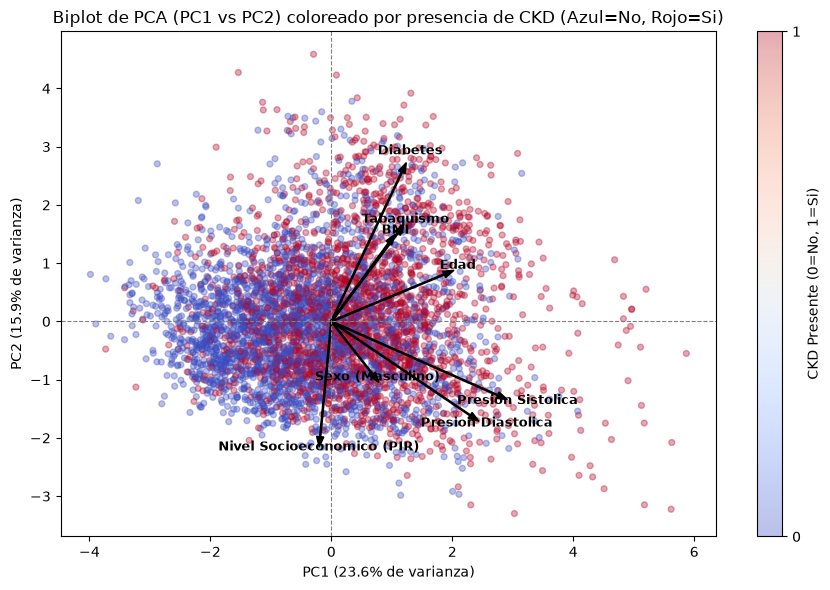

In [101]:
# graficamos el Biplot en el plano de las 2 primeras componentes pintando por CKD Presente
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    componentes[:, 0], componentes[:, 1],
    c=y, cmap="coolwarm", alpha=0.35, s=18
)

# superponemos las flechas de las variables originales
escala_flechas = 4.5
for i, nombre in enumerate(nombres_features):
    dx = pca.components_[0, i] * escala_flechas
    dy = pca.components_[1, i] * escala_flechas
    plt.arrow(0, 0, dx, dy, color="black", width=0.02, head_width=0.12)
    plt.text(dx * 1.12, dy * 1.12, nombre, color="black", fontsize=9, fontweight="bold", ha="center")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel(f"PC1 ({var_explicada[0]*100:.1f}% de varianza)")
plt.ylabel(f"PC2 ({var_explicada[1]*100:.1f}% de varianza)")
plt.title("Biplot de PCA (PC1 vs PC2) coloreado por presencia de CKD (Azul=No, Rojo=Si)")
plt.colorbar(scatter, ticks=[0, 1], label="CKD Presente (0=No, 1=Si)")
plt.tight_layout()
plt.show()

Del analisis del PCA y el Biplot sacamos conclusiones muy utiles:
- Las primeras dos componentes principales explican el 39.5% de la varianza total (23.6% la PC1 y 15.9% la PC2), y recien con 5 componentes se alcanza el 79% de la varianza. Como vimos en la Clase 6, cuando 2 componentes retienen menos del 40% de la varianza no conviene reemplazar las variables originales por solo 2 componentes para el modelo predictivo, porque perderiamos el 60% de la informacion.
- Sin embargo, el Biplot y las cargas de la PC1 nos muestran claramente como se agrupan las variables: en la PC1 aportan con el mismo signo positivo la Presion Sistolica (0.585), la Presion Diastolica (0.485), la Edad (0.414), el Tabaquismo (0.243), el BMI (0.219) y la Diabetes (0.207), y se ve en el grafico que los puntos rojos (pacientes con CKD = 1) se concentran hacia la derecha siguiendo la direccion de los vectores de Edad, Presion Sistolica y Diabetes. En sentido opuesto apunta el Nivel Socioeconomico (PIR).

Ahora pasamos a validar formalmente el vinculo con la probabilidad de presentar CKD entrenando un modelo de Regresion Logistica. Separamos los datos en entrenamiento (80%) y test (20%) usando stratify=y, estandarizamos ajustando el StandardScaler unicamente sobre X_train, y usamos GridSearchCV con regularizacion L2 para manejar la colinealidad que vimos entre las presiones y la edad.

In [ ]:
# dividimos en train y test (80% / 20%) manteniendo la proporcion de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=10
)

# estandarizamos ajustando el scaler unicamente con los datos de entrenamiento
scaler = StandardScaler()
scaler.fit(X_train)

X_train_stand = scaler.transform(X_train)
X_test_stand = scaler.transform(X_test)

# como vimos que hay colinealidad entre las presiones y la edad, probamos GridSearchCV con regularizacion L2 
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=10),
    param_grid, cv=5, scoring="accuracy"
)
grid_search.fit(X_train_stand, y_train)
best_logistic_model = grid_search.best_estimator_

# predecimos sobre los datos de test estandarizados
y_pred = best_logistic_model.predict(X_test_stand)

# calculamos exactitud y matriz de confusion
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Mejor hiperparametro C seleccionado por validacion cruzada:", grid_search.best_params_["C"])
print(f"Exactitud (Accuracy) en test: {acc:.4f} ({acc*100:.2f}%)")
print("Tasa de error en test:", round(1 - acc, 4))

# graficamos la matriz de confusion
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Sin CKD (0)", "Con CKD (1)"],
    yticklabels=["Sin CKD (0)", "Con CKD (1)"]
)
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.title("Matriz de Confusion en datos de Test")
plt.tight_layout()
plt.show()

Finalmente graficamos los coeficientes (pesos) que aprendio la Regresion Logistica para ver el impacto directo de cada variable sobre la probabilidad de presentar CKD cuando actuan todas juntas.

In [ ]:
# recuperamos los coeficientes del mejor modelo logistico
theta_logistic = best_logistic_model.coef_[0]

tabla_coeficientes = pd.DataFrame({
    "Variable": nombres_features,
    "Coeficiente": theta_logistic
}).sort_values(by="Coeficiente", ascending=False)

display(tabla_coeficientes.round(4))

# graficamos los coeficientes aprendidos
fig, ax = plt.subplots(figsize=(10, 5))
colores_coef = ["#d32f2f" if c > 0 else "#1976d2" for c in tabla_coeficientes["Coeficiente"]]
ax.barh(tabla_coeficientes["Variable"][::-1], tabla_coeficientes["Coeficiente"][::-1], color=colores_coef[::-1], edgecolor="black")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Valor del coeficiente (peso en la Regresion Logistica)")
ax.set_title("Coeficientes aprendidos por la Regresion Logistica sobre la probabilidad de CKD")
plt.tight_layout()
plt.show()

Conclusion final integrando todos los pasos:
1. El modelo multivariado de Regresion Logistica alcanza una exactitud cercana al 70% (69.83%) en el conjunto de test, confirmando que la combinacion de estos atributos permite estimar la probabilidad de presentar CKD.
2. Analizando el signo de los coeficientes de la regresion logistica junto con la matriz de correlacion y el Biplot del PCA:
   - La Edad (+1.090), la Presion Sistolica (+0.188), el BMI (+0.049), la Diabetes (+0.044) y el Tabaquismo (+0.012) tienen tanto correlacion positiva como coeficientes positivos en la regresion, lo que demuestra que tienen un vinculo directo con la probabilidad de presentar CKD (a mayor valor de estas variables, mayor probabilidad de enfermedad).
   - Gracias a la matriz de correlacion que calculamos en el Paso 2, tambien se explica que pasa con la Presion Diastolica: como estaba fuertemente correlacionada con la Presion Sistolica (r = 0.61), la regularizacion L2 de la regresion logistica le asigna todo el peso a la Presion Sistolica (+0.188) y lleva el peso de la Diastolica casi a cero (-0.0025) para no duplicar la misma informacion. Lo mismo ocurre parcialmente con Diabetes y Tabaquismo al estar correlacionados con la Edad.
   - Por ultimo, el Nivel Socioeconomico (poverty_income_ratio) presenta un coeficiente negativo (-0.0074) y apunta en sentido contrario en el Biplot, indicando un vinculo inverso: a mayor nivel socioeconomico, menor probabilidad de presentar CKD.

Por lo tanto, la hipotesis se valida parcialmente: existe una clara relacion multivariada con la probabilidad de presentar CKD impulsada de forma directa por la edad, la presion arterial sistolica, el BMI, la diabetes y el tabaquismo, mientras que el nivel socioeconomico actua de forma inversa.